# Nashik Air-Quality Prediction with KNN Imputation and CNN-LSTM

One-step-ahead (next-hour) prediction of seven criteria pollutants at four Nashik
monitoring stations. Each station gets its own CNN-LSTM, trained on that station's
history only. The latest calendar year of each station is held out as the test set.

Run top to bottom. In Colab, the upload cell asks for the four station CSVs
(or the zip they came in).

## 1. Environment setup and imports

In [1]:
import glob
import json
import os
import platform
import zipfile

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow

OUT = "outputs"
for sub in ("figures", "metrics", "models", "predictions", "tables"):
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

VERSIONS = {
    "python": platform.python_version(), "tensorflow": tf.__version__,
    "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
print(VERSIONS)

{'python': '3.12.14', 'tensorflow': '2.19.0', 'pandas': '2.2.2', 'numpy': '2.0.2', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


## 2. Dataset upload and loading

Station identity comes from the file name: the four files share one schema and none
contains a station column. Hirwadi's file carries an extra `Source_File` column whose
labels do not match its timestamps (e.g. `2023.csv.csv` holds 2026 rows), so it is
dropped and the `Timestamp` column is treated as authoritative.

In [2]:
try:
    from google.colab import files  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
if IN_COLAB and not glob.glob(f"{DATA_DIR}/*.[cC][sS][vV]"):
    print("Select the four station CSVs (or their zip), plus build_report.py if you want "
          "the DOCX report generated in Colab.")
    os.makedirs("scripts", exist_ok=True)
    for name in files.upload():
        os.replace(name, f"scripts/{name}" if name.endswith(".py") else f"{DATA_DIR}/{name}")
for z in glob.glob(f"{DATA_DIR}/*.zip"):
    with zipfile.ZipFile(z) as zf:
        for member in zf.namelist():
            if member.lower().endswith(".csv"):
                with open(f"{DATA_DIR}/{os.path.basename(member)}", "wb") as fh:
                    fh.write(zf.read(member))

STATION_PATTERNS = {  # file-name fragment -> station label used everywhere below
    "midcambad": "MIDC Ambad", "gangapur": "Gangapur Road",
    "pandav": "Pandav Nagari", "hirwadi": "Hirwadi",
}


def find_station_files(data_dir):
    found = {}
    for path in glob.glob(f"{data_dir}/*"):
        key = os.path.basename(path).lower().replace("_", "").replace(" ", "")
        for frag, station in STATION_PATTERNS.items():
            if frag in key and path.lower().endswith(".csv"):
                found[station] = path
    missing = set(STATION_PATTERNS.values()) - set(found)
    if missing:
        raise FileNotFoundError(f"No CSV found in '{data_dir}/' for: {sorted(missing)}. "
                                "Upload the four Nashik station files.")
    return {station: found[station] for station in STATION_PATTERNS.values()}


STATION_FILES = find_station_files(DATA_DIR)
raw = {s: pd.read_csv(p) for s, p in STATION_FILES.items()}
for s, d in raw.items():
    print(f"{s:14s} {STATION_FILES[s]:45s} rows={len(d):6d} cols={d.shape[1]}")

MIDC Ambad     data/MIDCAMBAD_NASHIK.CSV                     rows= 40152 cols=25
Gangapur Road  data/combined_gangapur_road_nashik.csv        rows= 81024 cols=25
Pandav Nagari  data/combined_pandav_nagari_nashik.csv        rows= 35064 cols=25
Hirwadi        data/hirwadi_nashik.csv                       rows= 40152 cols=26


## 3. Dataset inspection and data dictionary

In [3]:
TARGETS = {  # standardised name -> original column (CPCB-AQI pollutants present in the data)
    "PM2.5": "PM2.5 (µg/m³)", "PM10": "PM10 (µg/m³)", "NO2": "NO2 (µg/m³)",
    "SO2": "SO2 (µg/m³)", "CO": "CO (mg/m³)", "O3": "Ozone (µg/m³)", "NH3": "NH3 (µg/m³)",
}
UNITS = {"PM2.5": "µg/m³", "PM10": "µg/m³", "NO2": "µg/m³", "SO2": "µg/m³",
         "CO": "mg/m³", "O3": "µg/m³", "NH3": "µg/m³"}
POLL = list(TARGETS)
EXPECTED = ["Timestamp", *TARGETS.values()]
for s, d in raw.items():
    absent = [c for c in EXPECTED if c not in d.columns]
    if absent:
        raise KeyError(f"{s}: expected columns not found: {absent}")
    if d.empty:
        raise ValueError(f"{s}: file is empty")


def column_role(col):
    if col == "Timestamp":
        return "timestamp"
    if col == "Source_File":
        return "metadata (dropped: labels inconsistent with timestamps)"
    if col in TARGETS.values():
        return "pollutant - model input and prediction target"
    if col.split(" (")[0] in {"AT", "RH", "WS", "WD", "RF", "TOT-RF", "SR", "BP", "VWS"}:
        return "meteorology - not used (see report)"
    return "pollutant (VOC/NOx species) - not used"


rows = []
for col in raw["Gangapur Road"].columns.union(raw["Hirwadi"].columns, sort=False):
    entry = {"original_column": col, "role": column_role(col),
             "unit": col.split("(")[-1].rstrip(")") if "(" in col else ""}
    for s, d in raw.items():
        entry[f"missing_%_{s}"] = round(100 * d[col].isna().mean(), 1) if col in d else None
    rows.append(entry)
data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv(f"{OUT}/tables/data_dictionary.csv", index=False)
data_dictionary

,original_column,role,unit,missing_%_MIDC Ambad,missing_%_Gangapur Road,missing_%_Pandav Nagari,missing_%_Hirwadi
0,Timestamp,timestamp,,0.0,0.0,0.0,0.0
1,PM2.5 (µg/m³),pollutant - model input and prediction target,µg/m³,36.6,11.3,37.4,35.5
2,PM10 (µg/m³),pollutant - model input and prediction target,µg/m³,36.6,11.5,37.2,35.5
3,NO (µg/m³),pollutant (VOC/NOx species) - not used,µg/m³,38.8,11.1,38.1,36.4
4,NO2 (µg/m³),pollutant - model input and prediction target,µg/m³,37.0,11.1,37.3,35.8
5,NOx (ppb),pollutant (VOC/NOx species) - not used,ppb,37.0,9.9,37.2,35.5
6,NH3 (µg/m³),pollutant - model input and prediction target,µg/m³,37.3,12.8,37.2,36.2
7,SO2 (µg/m³),pollutant - model input and prediction target,µg/m³,36.7,9.4,37.1,37.2
8,CO (mg/m³),pollutant - model input and prediction target,mg/m³,36.4,6.7,36.7,34.9
9,Ozone (µg/m³),pollutant - model input and prediction target,µg/m³,36.2,11.0,36.9,35.5


In [4]:
inspection = []
for s, d in raw.items():
    ts = pd.to_datetime(d["Timestamp"], errors="raise")
    steps = ts.sort_values().diff().value_counts()
    inspection.append({
        "station": s, "rows": len(d), "first": ts.min(), "last": ts.max(),
        "duplicate_timestamps": int(ts.duplicated().sum()),
        "sorted_in_file": bool(ts.is_monotonic_increasing),
        "modal_step": str(steps.index[0]), "irregular_steps": int(steps.iloc[1:].sum()),
        "years_present": ", ".join(str(y) for y in sorted(ts.dt.year.unique())),
        "all_pollutants_missing_rows": int(d[list(TARGETS.values())].isna().all(axis=1).sum()),
    })
inspection = pd.DataFrame(inspection)
inspection.to_csv(f"{OUT}/tables/dataset_inspection.csv", index=False)
inspection

,station,rows,first,last,duplicate_timestamps,sorted_in_file,modal_step,irregular_steps,years_present,all_pollutants_missing_rows
0,MIDC Ambad,40152,2017-01-01,2026-08-31 23:00:00,0,True,0 days 01:00:00,2,"2017, 2023, 2024, 2025, 2026",14377
1,Gangapur Road,81024,2017-01-01,2026-08-31 23:00:00,0,True,0 days 01:00:00,2,"2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024...",4945
2,Pandav Nagari,35064,2017-01-01,2025-12-31 23:00:00,0,True,0 days 01:00:00,1,"2017, 2023, 2024, 2025",12761
3,Hirwadi,40152,2017-01-01,2026-08-31 23:00:00,0,False,0 days 01:00:00,2,"2017, 2023, 2024, 2025, 2026",13873


## 4. Data-quality checks, cleaning and exploratory analysis

Cleaning rules (applied per station, counts logged):
1. Sort by timestamp; duplicate timestamps would keep the first row (none occur).
2. Drop rows before the station's first pollutant observation (the 2017 placeholder
   blocks at three stations are entirely empty).
3. Negative concentrations -> missing (none occur).
4. PM2.5 / PM10 >= 999 -> missing: the analyser ceiling, not a measurement.
5. A value repeated unchanged for >= 12 consecutive hours -> missing (stuck sensor,
   mostly CO flat at 0.00 mg/m³).

No resampling or aggregation: one observation = one hourly average as reported.
Time gaps (rows absent from the file) are not filled; sequences never span them.

In [5]:
STUCK_HOURS = 12
PM_CEILING = 999


def clean_station(df):
    df = df.copy()
    df["Timestamp"] = pd.to_datetime(df["Timestamp"])
    df = df.sort_values("Timestamp", kind="stable").reset_index(drop=True)
    log = {"duplicates_removed": int(df["Timestamp"].duplicated().sum())}
    df = df.drop_duplicates("Timestamp", keep="first").reset_index(drop=True)
    df = df.rename(columns={v: k for k, v in TARGETS.items()})[["Timestamp", *POLL]]
    first_obs = int(df[POLL].notna().any(axis=1).idxmax())
    log["leading_empty_rows_dropped"] = first_obs
    df = df.iloc[first_obs:].reset_index(drop=True)
    for c in POLL:
        neg = df[c] < 0
        ceiling = (df[c] >= PM_CEILING) if c in ("PM2.5", "PM10") else pd.Series(False, df.index)
        run_id = (df[c] != df[c].shift()).cumsum()
        stuck = (df[c].groupby(run_id).transform("size") >= STUCK_HOURS) & df[c].notna()
        log[f"{c}_negative"] = int(neg.sum())
        log[f"{c}_ceiling"] = int(ceiling.sum())
        log[f"{c}_stuck"] = int(stuck.sum())
        df.loc[neg | ceiling | stuck, c] = np.nan
    return df, log


clean, cleaning_log = {}, {}
for s, d in raw.items():
    clean[s], cleaning_log[s] = clean_station(d)
cleaning_log = pd.DataFrame(cleaning_log).T
cleaning_log.to_csv(f"{OUT}/tables/cleaning_log.csv")
print("Retained period per station:")
for s, d in clean.items():
    gaps = d["Timestamp"].diff()
    big = gaps[gaps > pd.Timedelta(hours=1)]
    print(f"  {s:14s} {d.Timestamp.min()} -> {d.Timestamp.max()}  rows={len(d)}  "
          f"absent-row gaps: {[str(g) for g in big]}")
cleaning_log

Retained period per station:
  MIDC Ambad     2023-06-14 14:00:00 -> 2026-08-31 23:00:00  rows=27442  absent-row gaps: ['31 days 01:00:00']
  Gangapur Road  2017-01-01 00:00:00 -> 2026-08-31 23:00:00  rows=81024  absent-row gaps: ['123 days 01:00:00', '31 days 01:00:00']
  Pandav Nagari  2023-05-22 17:00:00 -> 2025-12-31 23:00:00  rows=22903  absent-row gaps: []
  Hirwadi        2023-05-23 16:00:00 -> 2026-08-31 23:00:00  rows=27968  absent-row gaps: ['31 days 01:00:00']


,duplicates_removed,leading_empty_rows_dropped,PM2.5_negative,PM2.5_ceiling,PM2.5_stuck,PM10_negative,PM10_ceiling,PM10_stuck,NO2_negative,NO2_ceiling,...,SO2_stuck,CO_negative,CO_ceiling,CO_stuck,O3_negative,O3_ceiling,O3_stuck,NH3_negative,NH3_ceiling,NH3_stuck
MIDC Ambad,0,12710,0,0,22,0,0,0,0,0,...,0,0,0,3059,0,0,14,0,0,12
Gangapur Road,0,0,0,1,346,0,20,124,0,0,...,193,0,0,4005,0,0,155,0,0,806
Pandav Nagari,0,12161,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Hirwadi,0,12184,0,0,13,0,0,13,0,0,...,0,0,0,2247,0,0,0,0,0,0


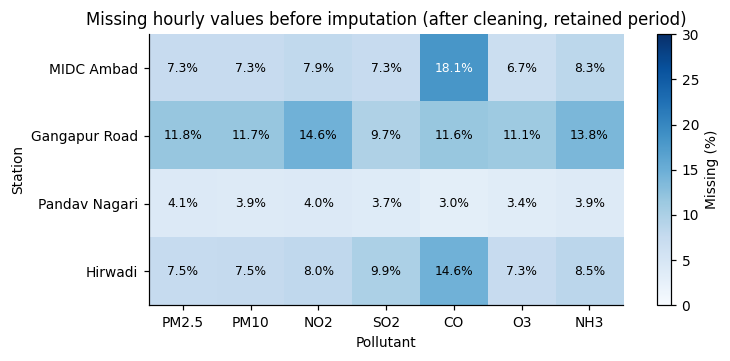

In [6]:
STATION_COLORS = {"MIDC Ambad": "#2a78d6", "Gangapur Road": "#eb6834",
                  "Pandav Nagari": "#1baf7a", "Hirwadi": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def savefig(fig, name):
    fig.savefig(f"{OUT}/figures/{name}.png", bbox_inches="tight")
    plt.show()


miss = pd.DataFrame({s: 100 * d[POLL].isna().mean() for s, d in clean.items()}).T
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(miss.values, cmap="Blues", vmin=0, vmax=max(30, miss.values.max()))
ax.set_xticks(range(len(POLL)), POLL)
ax.set_yticks(range(len(miss)), miss.index)
for i in range(miss.shape[0]):
    for j in range(miss.shape[1]):
        v = miss.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=8,
                color="white" if v > 0.6 * im.get_clim()[1] else "black")
ax.grid(False)
ax.set_xlabel("Pollutant")
ax.set_ylabel("Station")
ax.set_title("Missing hourly values before imputation (after cleaning, retained period)")
fig.colorbar(im, ax=ax, label="Missing (%)")
savefig(fig, "fig01_missing_values")
miss.round(2).to_csv(f"{OUT}/tables/missing_pct_before_imputation.csv")

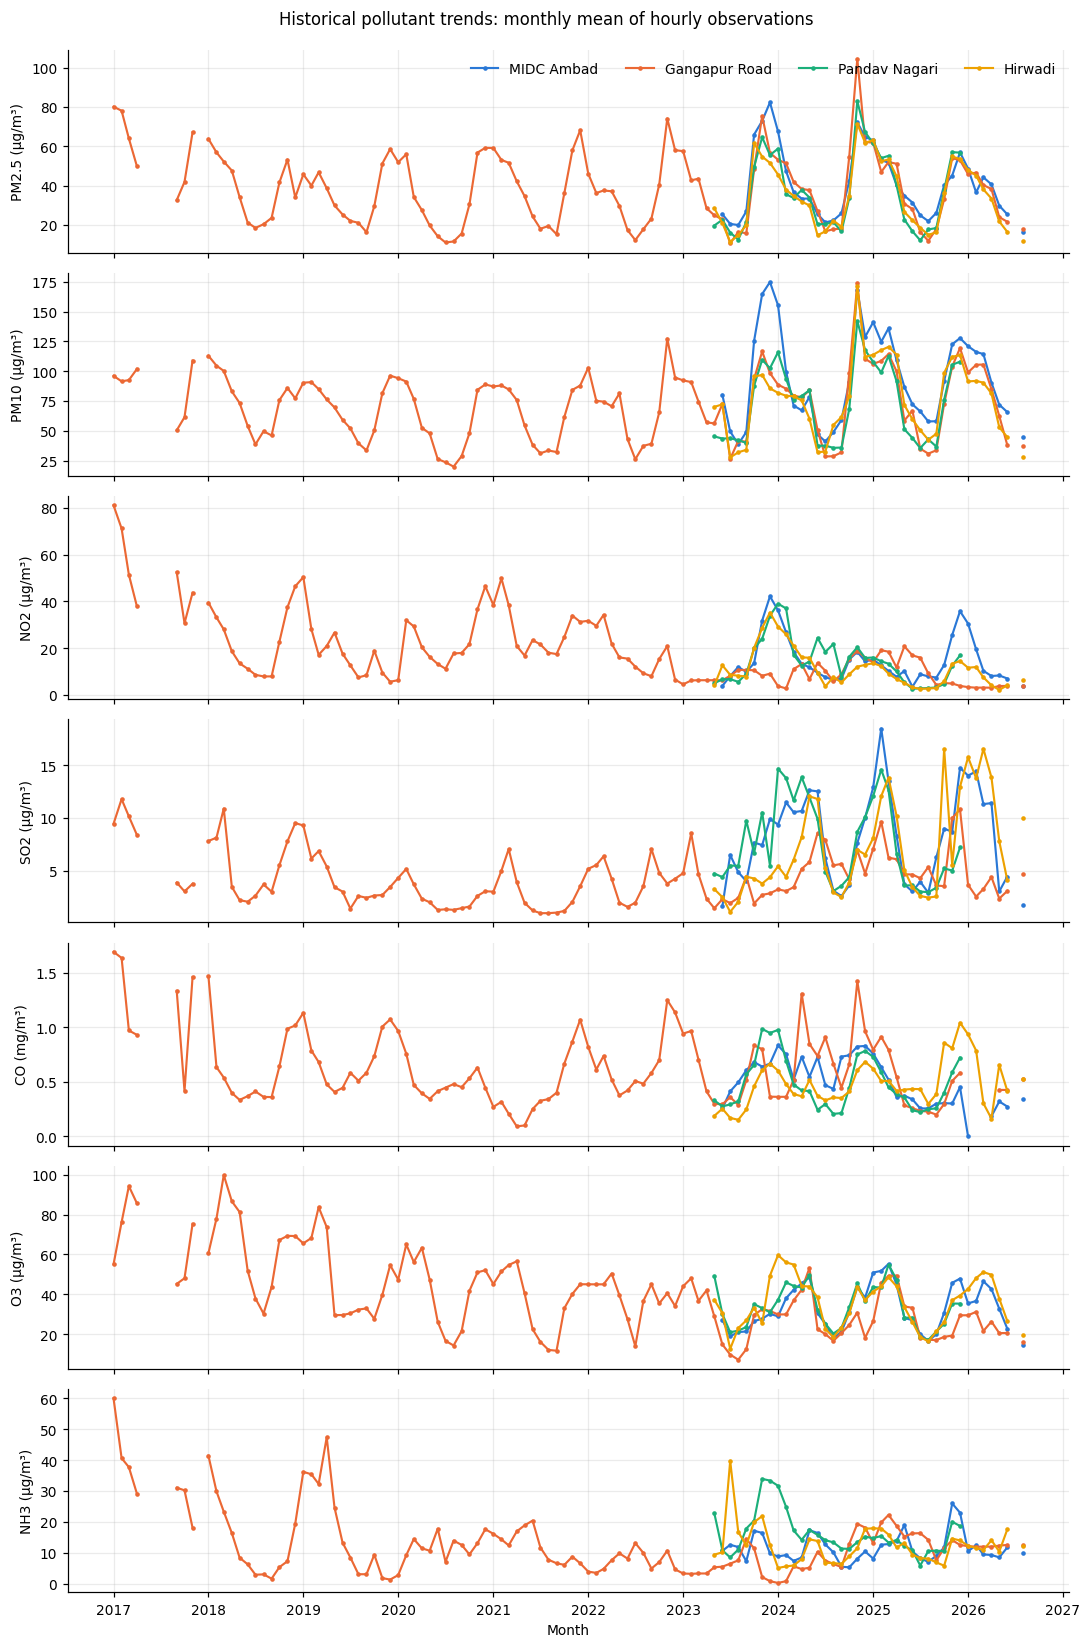

In [7]:
fig, axes = plt.subplots(len(POLL), 1, figsize=(10, 15), sharex=True)
for ax, p in zip(axes, POLL):
    for s, d in clean.items():
        m = d.set_index("Timestamp")[p].resample("MS").mean()
        ax.plot(m.index, m.values, lw=1.4, marker="o", ms=2, color=STATION_COLORS[s], label=s)
    ax.set_ylabel(f"{p} ({UNITS[p]})")
axes[0].legend(ncol=4, loc="upper right", frameon=False)
axes[-1].set_xlabel("Month")
fig.suptitle("Historical pollutant trends: monthly mean of hourly observations", y=0.995)
fig.tight_layout()
savefig(fig, "fig02_historical_trends")

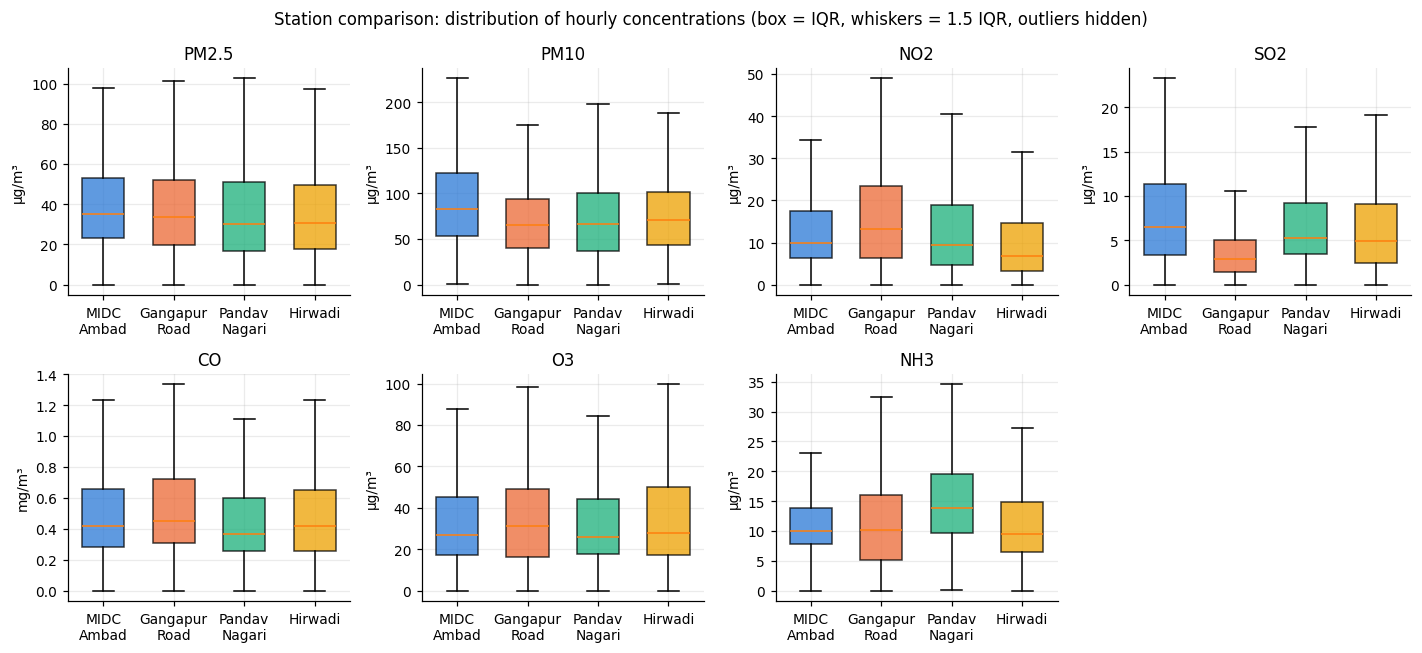

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, p in zip(axes.flat, POLL):
    data = [clean[s][p].dropna().values for s in clean]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6)
    for patch, s in zip(bp["boxes"], clean):
        patch.set_facecolor(STATION_COLORS[s])
        patch.set_alpha(0.75)
    ax.set_xticks(range(1, len(clean) + 1), [s.replace(" ", "\n") for s in clean])
    ax.set_title(p)
    ax.set_ylabel(UNITS[p])
axes.flat[-1].axis("off")
fig.suptitle("Station comparison: distribution of hourly concentrations "
             "(box = IQR, whiskers = 1.5 IQR, outliers hidden)")
fig.tight_layout()
savefig(fig, "fig03_station_comparison")

summary_stats = pd.concat({s: d[POLL].describe().T for s, d in clean.items()})
summary_stats.round(2).to_csv(f"{OUT}/tables/descriptive_statistics.csv")

## 5. Chronological train / validation / test split

The test set is each station's latest calendar year with observations. Three stations
end in 2026 (Jan-Jun and Aug; July 2026 is absent from all files). Pandav Nagari ends
on 2025-12-31, so its test year is 2025. Validation is the six months before the
test year; training is everything earlier. The split is by the timestamp of the
predicted hour, so no test-year label is used for fitting, early stopping or tuning.

In [9]:
def split_bounds(df):
    test_year = df["Timestamp"].dt.year.max()
    test_start = pd.Timestamp(f"{test_year}-01-01")
    val_start = test_start - pd.DateOffset(months=6)
    return test_year, val_start, test_start


def split_label(ts, val_start, test_start):
    return np.where(ts >= test_start, "test", np.where(ts >= val_start, "val", "train"))


split_rows = []
for s, d in clean.items():
    test_year, val_start, test_start = split_bounds(d)
    lab = split_label(d["Timestamp"], val_start, test_start)
    for part in ("train", "val", "test"):
        sub = d[lab == part]
        split_rows.append({
            "station": s, "split": part, "start": sub.Timestamp.min(),
            "end": sub.Timestamp.max(), "hourly_rows": len(sub),
            "test_year": test_year,
            "months_present": sub.Timestamp.dt.to_period("M").nunique(),
            "pm25_observed": int(sub["PM2.5"].notna().sum()),
        })
splits = pd.DataFrame(split_rows)
splits.to_csv(f"{OUT}/tables/splits.csv", index=False)
splits

,station,split,start,end,hourly_rows,test_year,months_present,pm25_observed
0,MIDC Ambad,train,2023-06-14 14:00:00,2025-06-30 23:00:00,17938,2026,25,16560
1,MIDC Ambad,val,2025-07-01 00:00:00,2025-12-31 23:00:00,4416,2026,6,4175
2,MIDC Ambad,test,2026-01-01 00:00:00,2026-08-31 23:00:00,5088,2026,7,4708
3,Gangapur Road,train,2017-01-01 00:00:00,2025-06-30 23:00:00,71520,2026,98,62415
4,Gangapur Road,val,2025-07-01 00:00:00,2025-12-31 23:00:00,4416,2026,6,4197
5,Gangapur Road,test,2026-01-01 00:00:00,2026-08-31 23:00:00,5088,2026,7,4876
6,Pandav Nagari,train,2023-05-22 17:00:00,2024-06-30 23:00:00,9727,2025,14,9439
7,Pandav Nagari,val,2024-07-01 00:00:00,2024-12-31 23:00:00,4416,2025,6,4251
8,Pandav Nagari,test,2025-01-01 00:00:00,2025-12-31 23:00:00,8760,2025,12,8277
9,Hirwadi,train,2023-05-23 16:00:00,2025-06-30 23:00:00,18464,2026,26,16799


## 6. KNN imputation and feature scaling

Per station: a `StandardScaler` (pollutants differ in units and range, e.g. CO in
mg/m³ vs PM10 in hundreds of µg/m³) and a `KNNImputer` (k=5, distance-weighted,
NaN-Euclidean distance) are fitted on that station's **training rows only**, then
applied to validation and test rows. Donors are therefore always training-period
hours; no future observation influences any imputed value.

Distance uses only the seven pollutant concentrations of the same hour - no station
ID, no timestamp. A missing value at hour s is filled from the other pollutants
observed at hour s, which are known by the time a forecast is issued for any hour
after s. Imputed values are used **only as model inputs**; prediction targets and
all evaluation use observed values only. Hours with every pollutant missing get the
training mean (KNN has no distance to work with); windows dominated by such hours
are excluded in step 7.

In [10]:
K_NEIGHBORS = 5
prep = {}
imputation_counts = []
for s, d in clean.items():
    test_year, val_start, test_start = split_bounds(d)
    lab = split_label(d["Timestamp"], val_start, test_start)
    train_mask = lab == "train"
    scaler = StandardScaler().fit(d.loc[train_mask, POLL])
    Xs = scaler.transform(d[POLL])
    imputer = KNNImputer(n_neighbors=K_NEIGHBORS, weights="distance").fit(Xs[train_mask])
    # macOS Accelerate BLAS raises spurious FP flags in sklearn's nan-euclidean matmul;
    # distances were checked against a direct computation, and the assert guards results.
    with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
        Xi = imputer.transform(Xs)
    assert np.isfinite(Xi).all(), f"{s}: imputation left non-finite values"
    observed = d[POLL].notna().values
    prep[s] = {"df": d, "split": lab, "scaler": scaler, "imputer": imputer,
               "X_imputed_scaled": Xi, "observed": observed}
    for part in ("train", "val", "test"):
        m = lab == part
        before = (~observed[m]).sum(axis=0)
        after = np.isnan(Xi[m]).sum(axis=0)
        for p, b, a in zip(POLL, before, after):
            imputation_counts.append({"station": s, "split": part, "pollutant": p,
                                      "missing_before": int(b), "missing_after": int(a)})
    joblib.dump({"scaler": scaler, "imputer": imputer, "features": POLL},
                f"{OUT}/models/preprocessing_{s.replace(' ', '_')}.joblib")
imputation_counts = pd.DataFrame(imputation_counts)
imputation_counts.to_csv(f"{OUT}/tables/imputation_counts.csv", index=False)
imputation_counts.pivot_table(index=["station", "split"], columns="pollutant",
                              values="missing_before").astype(int)

pollutant              CO    NH3   NO2    O3  PM10  PM2.5   SO2
station       split                                            
Gangapur Road test   3335    823  2848   101   232    212   759
              train  5944  10116  8761  8780  9041   9105  6875
              val     149    238   239   153   223    219   202
Hirwadi       test   2564    456   568   309   321    319   515
              train  1420   1792  1557  1644  1656   1665  1907
              val      99    122   108   101   124    110   350
MIDC Ambad    test   3417    434   459   370   378    380   380
              train  1359   1573  1442  1280  1405   1378  1365
              val     189    283   259   201   221    241   270
Pandav Nagari test    346    398   413   410   451    483   435
              train   199    309   334   244   272    288   252
              val     147    191   169   128   168    165   153

## 7. Sliding-window sequence generation

One observation = one hourly average. Input: the previous **24 hours** (one diurnal
cycle) of 13 features - 7 scaled, KNN-imputed pollutants plus sine/cosine encodings
of hour-of-day, day-of-week and month (deterministic, known in advance). Target: the
7 pollutants at the **next hour** (horizon = 1). A window is kept only if
- its 25 timestamps are consecutive hours (no window crosses a gap in the file),
- at least one target pollutant is observed at the predicted hour, and
- at most 50% of its input pollutant cells were imputed, and
- every pollutant has at least one earlier observation (needed by the baseline).

This is a one-step-ahead (nowcasting) design: at each test hour the model sees the
actual observations of the preceding 24 hours, as an operational system would. It
is not a recursive multi-step forecast and makes no claim about predicting a year
ahead.

In [11]:
LOOKBACK = 24
MAX_IMPUTED_FRACTION = 0.5


def calendar_features(ts):
    h, dow, mon = ts.dt.hour.values, ts.dt.dayofweek.values, ts.dt.month.values - 1
    return np.column_stack([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                            np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7),
                            np.sin(2 * np.pi * mon / 12), np.cos(2 * np.pi * mon / 12)])


def make_windows(p):
    d = p["df"]
    feats = np.column_stack([p["X_imputed_scaled"], calendar_features(d["Timestamp"])])
    feats = feats.astype("float32")
    y_raw = d[POLL].values.astype("float32")  # NaN where not observed
    y_scaled = ((y_raw - p["scaler"].mean_) / p["scaler"].scale_).astype("float32")
    hours = (d["Timestamp"].values.astype("datetime64[h]").astype("int64"))
    t = np.arange(LOOKBACK, len(d))
    contiguous = hours[t] - hours[t - LOOKBACK] == LOOKBACK
    imputed_frac = np.lib.stride_tricks.sliding_window_view(
        (~p["observed"]).mean(axis=1), LOOKBACK)[:-1].mean(axis=1)
    last_obs = d[POLL].ffill().values  # most recent observed value at or before each hour
    keep = (contiguous & ~np.isnan(y_raw[t]).all(axis=1)
            & (imputed_frac <= MAX_IMPUTED_FRACTION) & np.isfinite(last_obs[t - 1]).all(axis=1))
    t = t[keep]
    X = np.stack([feats[i - LOOKBACK:i] for i in t])
    last_scaled = ((last_obs[t - 1] - p["scaler"].mean_) / p["scaler"].scale_).astype("float32")
    return {"X": X, "y_scaled": y_scaled[t], "y_raw": y_raw[t], "t": t,
            "timestamp": d["Timestamp"].values[t], "split": p["split"][t],
            "persistence": last_obs[t - 1], "last_scaled": last_scaled}


windows = {s: make_windows(p) for s, p in prep.items()}
seq_rows = []
for s, w in windows.items():
    for part in ("train", "val", "test"):
        n = int((w["split"] == part).sum())
        if n == 0:
            raise ValueError(f"{s}: no {part} sequences - check the data and split dates")
        seq_rows.append({"station": s, "split": part, "sequences": n})
    print(f"{s:14s} X shape {w['X'].shape}  (samples, lookback hours, features)")
pd.DataFrame(seq_rows).pivot(index="station", columns="split", values="sequences")

MIDC Ambad     X shape (25248, 24, 13)  (samples, lookback hours, features)
Gangapur Road  X shape (73965, 24, 13)  (samples, lookback hours, features)
Pandav Nagari  X shape (22050, 24, 13)  (samples, lookback hours, features)
Hirwadi        X shape (25958, 24, 13)  (samples, lookback hours, features)


split,test,train,val
station,,,
Gangapur Road,4907,64835,4223
Hirwadi,4704,16951,4303
MIDC Ambad,4572,16498,4178
Pandav Nagari,8287,9499,4264


## 8. CNN-LSTM model definition

Conv1D layers learn short local temporal motifs (e.g. rush-hour rises) across the 24
hourly steps; max-pooling halves the sequence; an LSTM reads the pooled feature
sequence for longer-range dependencies; dropout regularises; a dense head outputs all
7 pollutants (multi-output). Missing targets are masked out of the MSE loss.

Two target parameterisations of the same network are trained and the one with the
lower **validation** loss is selected per station (the test year plays no part):
- `level`: predict the standardised concentration at the next hour;
- `change`: predict the change from the last observed value, then add it back.
Hourly pollution is strongly autocorrelated, so `change` lets the network spend its
capacity on the departure from persistence. In standardised units both losses
measure the same next-hour error, so their validation losses are directly comparable.

In [12]:
N_FEATURES = len(POLL) + 6


def masked_mse(y_true, y_pred):
    mask = tf.math.is_finite(y_true)
    err = tf.where(mask, y_true - y_pred, tf.zeros_like(y_pred))
    return tf.reduce_sum(tf.square(err)) / tf.maximum(tf.reduce_sum(tf.cast(mask, tf.float32)), 1.0)


def build_cnn_lstm():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, N_FEATURES)),
        tf.keras.layers.Conv1D(64, 3, padding="causal", activation="relu"),
        tf.keras.layers.Conv1D(64, 3, padding="causal", activation="relu"),
        tf.keras.layers.MaxPooling1D(2),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(len(POLL)),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=masked_mse)
    return model


build_cnn_lstm().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 24, 64)         │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,247 (196.28 KB)

 Trainable params: 50,247 (196.28 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Model training and validation

Adam (lr 1e-3), batch 256, up to 60 epochs, early stopping on validation loss with
patience 6 and best-weights restore. No hyperparameter search: one fixed
configuration for all stations.

In [13]:
BATCH, EPOCHS, PATIENCE = 256, 60, 6
DESIGNS = ("level", "change")


def design_target(w, design):
    return w["y_scaled"] - w["last_scaled"] if design == "change" else w["y_scaled"]


models, histories, selection = {}, {}, []
for s, w in windows.items():
    tr, va = w["split"] == "train", w["split"] == "val"
    row = {"station": s, "train_sequences": int(tr.sum()), "val_sequences": int(va.sum()),
           "val_loss_persistence": float(np.nanmean(
               np.square(w["y_scaled"][va] - w["last_scaled"][va])))}
    for design in DESIGNS:
        tf.keras.utils.set_random_seed(SEED)
        y = design_target(w, design)
        model = build_cnn_lstm()
        hist = model.fit(
            w["X"][tr], y[tr], validation_data=(w["X"][va], y[va]),
            epochs=EPOCHS, batch_size=BATCH, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(patience=PATIENCE,
                                                        restore_best_weights=True)])
        models[(s, design)], histories[f"{s}|{design}"] = model, hist.history
        best = int(np.argmin(hist.history["val_loss"]))
        row.update({f"val_loss_{design}": hist.history["val_loss"][best],
                    f"train_loss_{design}": hist.history["loss"][best],
                    f"best_epoch_{design}": best + 1,
                    f"epochs_run_{design}": len(hist.history["loss"])})
        model.save(f"{OUT}/models/cnn_lstm_{design}_{s.replace(' ', '_')}.keras")
    row["selected_design"] = min(DESIGNS, key=lambda d: row[f"val_loss_{d}"])
    selection.append(row)
selection = pd.DataFrame(selection).set_index("station")
selection.to_csv(f"{OUT}/metrics/model_selection_validation.csv")
with open(f"{OUT}/metrics/training_history.json", "w") as fh:
    json.dump(histories, fh)
selection.round(4)

,train_sequences,val_sequences,val_loss_persistence,val_loss_level,train_loss_level,best_epoch_level,epochs_run_level,val_loss_change,train_loss_change,best_epoch_change,epochs_run_change,selected_design
station,,,,,,,,,,,,
MIDC Ambad,16498,4178,0.1625,0.1817,0.1960,24,30,0.1387,0.1768,13,19,change
Gangapur Road,64835,4223,0.1109,0.1293,0.2217,8,14,0.0926,0.1902,9,15,change
Pandav Nagari,9499,4264,0.2160,0.2312,0.1913,25,31,0.1756,0.1771,16,22,change
Hirwadi,16951,4303,0.3727,0.4120,0.2410,11,17,0.3065,0.2369,5,11,change


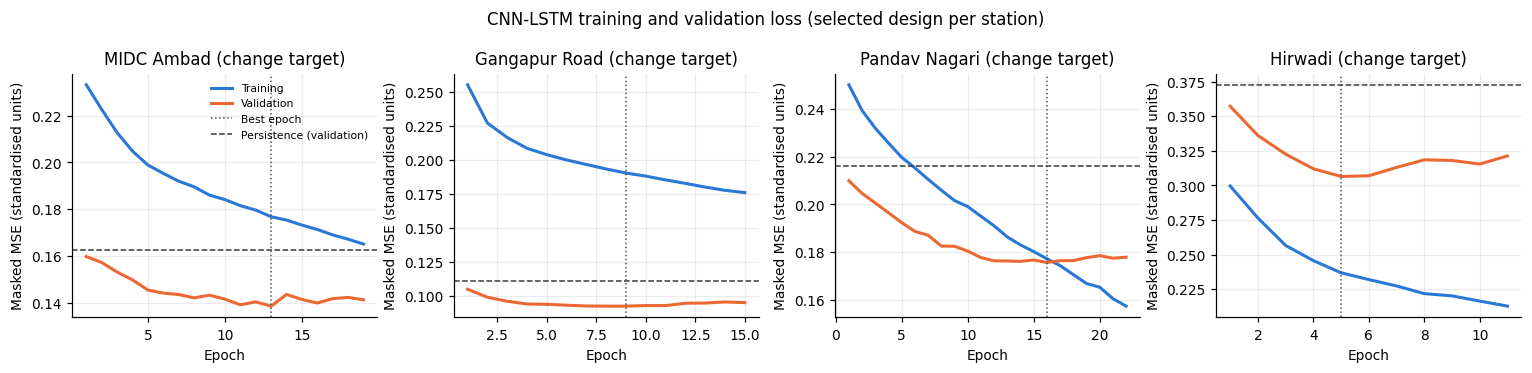

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, s in zip(axes, windows):
    h = histories[f"{s}|{selection.loc[s, 'selected_design']}"]
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], lw=2, color="#2a78d6", label="Training")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], lw=2, color="#eb6834",
            label="Validation")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, color="#52514e", ls=":", lw=1,
               label="Best epoch")
    ax.axhline(selection.loc[s, "val_loss_persistence"], color="#3b3b3b", lw=1, ls="--",
               label="Persistence (validation)")
    ax.set_title(f"{s} ({selection.loc[s, 'selected_design']} target)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked MSE (standardised units)")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("CNN-LSTM training and validation loss (selected design per station)")
fig.tight_layout()
savefig(fig, "fig04_loss_curves")

## 10-11. Test-year prediction and inverse transformation

Predictions are produced in standardised units and inverse-transformed with each
station's training scaler back to µg/m³ (mg/m³ for CO), then floored at 0 because a
concentration cannot be negative. Each row of the exported
table is one (station, hour, pollutant) with an observed actual value.

In [15]:
pred_rows = []
for s, w in windows.items():
    te = w["split"] == "test"
    sc = prep[s]["scaler"]
    yhat = {}
    for design in DESIGNS:
        z = models[(s, design)](w["X"][te], training=False).numpy()
        if design == "change":
            z = z + w["last_scaled"][te]
        yhat[design] = np.maximum(z * sc.scale_ + sc.mean_, 0)  # concentrations are >= 0
    chosen = selection.loc[s, "selected_design"]
    for j, p in enumerate(POLL):
        obs = ~np.isnan(w["y_raw"][te][:, j])
        pred_rows.append(pd.DataFrame({
            "station": s, "timestamp": w["timestamp"][te][obs], "pollutant": p,
            "unit": UNITS[p], "actual": w["y_raw"][te][obs, j],
            "cnn_lstm_pred": yhat[chosen][obs, j], "selected_design": chosen,
            "persistence_pred": w["persistence"][te][obs, j],
            "cnn_lstm_level_pred": yhat["level"][obs, j],
            "cnn_lstm_change_pred": yhat["change"][obs, j],
        }))
predictions = pd.concat(pred_rows, ignore_index=True)
predictions["test_year"] = pd.to_datetime(predictions["timestamp"]).dt.year
assert predictions.drop(columns="selected_design").notna().all().all()
predictions.to_csv(f"{OUT}/predictions/actual_vs_predicted.csv", index=False)
predictions.head()

,station,timestamp,pollutant,unit,actual,cnn_lstm_pred,selected_design,persistence_pred,cnn_lstm_level_pred,cnn_lstm_change_pred,test_year
0,MIDC Ambad,2026-01-01 00:00:00,PM2.5,µg/m³,46.75,55.477318,change,48.23,46.052336,55.477318,2026
1,MIDC Ambad,2026-01-01 01:00:00,PM2.5,µg/m³,46.00,52.207502,change,46.75,45.110395,52.207502,2026
2,MIDC Ambad,2026-01-01 02:00:00,PM2.5,µg/m³,42.00,48.524890,change,46.00,44.187814,48.524890,2026
3,MIDC Ambad,2026-01-01 03:00:00,PM2.5,µg/m³,40.25,43.648110,change,42.00,45.586268,43.648110,2026
4,MIDC Ambad,2026-01-01 04:00:00,PM2.5,µg/m³,43.00,42.955530,change,40.25,43.906598,42.955530,2026


## 12-13. Evaluation metrics and persistence baseline

MSE, RMSE, MAE and R² from scikit-learn, in original units, per station and
pollutant. The persistence baseline predicts the most recent observed value of the
same pollutant at or before the previous hour, on exactly the same test rows.
Skill = 1 - RMSE_model / RMSE_persistence (> 0 means the CNN-LSTM beats persistence).

Data-quality flag: a test series is flagged when it takes fewer than 100 distinct
values over the whole test period (e.g. Gangapur Road NO2 in 2026 reads mostly 3.00
µg/m³ in 0.25 steps, versus ~2,400 distinct values per year before). Flagged
series are reported but left out of the pooled all-station summary. The pooled summary
concatenates the hourly test rows of the unflagged stations for one pollutant (same
units), so stations with more test hours weigh more. Pollutants are never pooled together.

In [16]:
def metrics(y, yhat):
    mse = mean_squared_error(y, yhat)
    r2 = r2_score(y, yhat) if len(y) > 1 and np.var(y) > 0 else np.nan
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, yhat), "R2": r2}


def evaluate(groups):
    rows = []
    for keys, g in groups:
        base = dict(zip(["station", "pollutant"], keys)) if isinstance(keys, tuple) \
            else {"station": "All stations (pooled)", "pollutant": keys}
        period = ", ".join(f"{y}" for y in sorted(g["test_year"].unique()))
        start, end = pd.to_datetime(g.timestamp).min(), pd.to_datetime(g.timestamp).max()
        base.update({"evaluation_period": f"{start:%Y-%m-%d} to {end:%Y-%m-%d} ({period})",
                     "unit": g["unit"].iloc[0], "n_test_obs": len(g)})
        m, b = metrics(g.actual, g.cnn_lstm_pred), metrics(g.actual, g.persistence_pred)
        base.update({f"CNN-LSTM {k}": v for k, v in m.items()})
        base.update({f"Persistence {k}": v for k, v in b.items()})
        base["RMSE skill vs persistence"] = 1 - m["RMSE"] / b["RMSE"]
        base["level-design RMSE"] = metrics(g.actual, g.cnn_lstm_level_pred)["RMSE"]
        base["change-design RMSE"] = metrics(g.actual, g.cnn_lstm_change_pred)["RMSE"]
        rows.append(base)
    return pd.DataFrame(rows)


MIN_DISTINCT_VALUES = 100

station_metrics = evaluate(predictions.groupby(["station", "pollutant"], sort=False))
distinct = predictions.groupby(["station", "pollutant"], sort=False).actual.nunique()
station_metrics["distinct_test_values"] = distinct.values
station_metrics["quality_flag"] = station_metrics.distinct_test_values < MIN_DISTINCT_VALUES
flagged = set(zip(station_metrics.station[station_metrics.quality_flag],
                  station_metrics.pollutant[station_metrics.quality_flag]))
print("Flagged test series:", flagged)
unflagged = predictions[[(st, po) not in flagged
                         for st, po in zip(predictions.station, predictions.pollutant)]]
overall_metrics = evaluate(unflagged.groupby("pollutant", sort=False))
overall_metrics["stations_included"] = [
    ", ".join(unflagged[unflagged.pollutant == p].station.unique())
    for p in overall_metrics.pollutant]
station_metrics.to_csv(f"{OUT}/metrics/station_pollutant_metrics.csv", index=False)
overall_metrics.to_csv(f"{OUT}/metrics/overall_pollutant_metrics.csv", index=False)

skill_summary = station_metrics.pivot(index="station", columns="pollutant",
                                      values="RMSE skill vs persistence")[POLL]
skill_summary["mean skill (unflagged)"] = station_metrics[~station_metrics.quality_flag] \
    .groupby("station")["RMSE skill vs persistence"].mean()
skill_summary.round(3).to_csv(f"{OUT}/metrics/rmse_skill_summary.csv")

results_table = station_metrics[["station", "pollutant", "evaluation_period", "n_test_obs",
                                 "CNN-LSTM MSE", "CNN-LSTM RMSE", "CNN-LSTM MAE", "CNN-LSTM R2",
                                 "quality_flag"]]
results_table.round(3)

Flagged test series: {('MIDC Ambad', 'CO'), ('Gangapur Road', 'NO2'), ('Gangapur Road', 'NH3'), ('Gangapur Road', 'CO')}


,station,pollutant,evaluation_period,n_test_obs,CNN-LSTM MSE,CNN-LSTM RMSE,CNN-LSTM MAE,CNN-LSTM R2,quality_flag
0,MIDC Ambad,PM2.5,2026-01-01 to 2026-08-31 (2026),4542,35.711,5.976,3.981,0.866,False
1,MIDC Ambad,PM10,2026-01-01 to 2026-08-31 (2026),4544,238.575,15.446,8.786,0.854,False
2,MIDC Ambad,NO2,2026-01-01 to 2026-08-31 (2026),4467,25.870,5.086,2.794,0.840,False
3,MIDC Ambad,SO2,2026-01-01 to 2026-08-31 (2026),4542,5.725,2.393,1.278,0.864,False
4,MIDC Ambad,CO,2026-04-21 to 2026-08-31 (2026),1574,0.007,0.084,0.051,0.443,True
5,MIDC Ambad,O3,2026-01-01 to 2026-08-31 (2026),4552,41.553,6.446,4.464,0.890,False
6,MIDC Ambad,NH3,2026-01-01 to 2026-08-31 (2026),4489,1.908,1.381,0.899,0.748,False
7,Gangapur Road,PM2.5,2026-01-01 to 2026-08-31 (2026),4800,135.377,11.635,5.337,0.707,False
8,Gangapur Road,PM10,2026-01-01 to 2026-08-31 (2026),4780,350.087,18.711,10.797,0.811,False
9,Gangapur Road,NO2,2026-01-02 to 2026-08-31 (2026),2190,1.426,1.194,0.408,-1.101,True


In [17]:
overall_metrics.round(3)

,station,pollutant,evaluation_period,unit,n_test_obs,CNN-LSTM MSE,CNN-LSTM RMSE,CNN-LSTM MAE,CNN-LSTM R2,Persistence MSE,Persistence RMSE,Persistence MAE,Persistence R2,RMSE skill vs persistence,level-design RMSE,change-design RMSE,stations_included
0,All stations (pooled),PM2.5,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,22109,75.240,8.674,4.006,0.842,83.814,9.155,4.160,0.824,0.053,10.244,8.674,"MIDC Ambad, Gangapur Road, Pandav Nagari, Hirwadi"
1,All stations (pooled),PM10,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,22113,270.116,16.435,8.296,0.851,323.668,17.991,9.022,0.822,0.086,19.718,16.435,"MIDC Ambad, Gangapur Road, Pandav Nagari, Hirwadi"
2,All stations (pooled),NO2,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,17068,17.255,4.154,2.270,0.812,21.272,4.612,2.345,0.769,0.099,5.173,4.154,"MIDC Ambad, Pandav Nagari, Hirwadi"
3,All stations (pooled),SO2,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,21414,29.208,5.404,1.883,0.654,34.719,5.892,1.862,0.588,0.083,6.033,5.404,"MIDC Ambad, Gangapur Road, Pandav Nagari, Hirwadi"
4,All stations (pooled),O3,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,22301,71.827,8.475,4.575,0.834,88.095,9.386,5.012,0.796,0.097,10.234,8.475,"MIDC Ambad, Gangapur Road, Pandav Nagari, Hirwadi"
5,All stations (pooled),NH3,"2025-01-02 to 2026-08-31 (2025, 2026)",µg/m³,17213,27.965,5.288,2.143,0.461,30.183,5.494,1.994,0.419,0.037,5.394,5.288,"MIDC Ambad, Pandav Nagari, Hirwadi"
6,All stations (pooled),CO,"2025-01-02 to 2026-08-31 (2025, 2026)",mg/m³,10673,0.022,0.147,0.076,0.806,0.027,0.165,0.080,0.757,0.106,0.183,0.147,"Pandav Nagari, Hirwadi"


In [18]:
skill_summary.round(3)

pollutant,PM2.5,PM10,NO2,SO2,CO,O3,NH3,mean skill (unflagged)
station,,,,,,,,
Gangapur Road,0.051,0.068,-0.091,0.062,-4.196,0.004,0.030,0.046
Hirwadi,0.061,0.052,0.021,0.073,0.054,0.077,0.034,0.053
MIDC Ambad,0.021,0.141,0.146,0.042,-0.003,0.161,-0.003,0.085
Pandav Nagari,0.059,0.093,0.080,0.098,0.127,0.146,0.045,0.093


## 14. Visualisations of test-year results

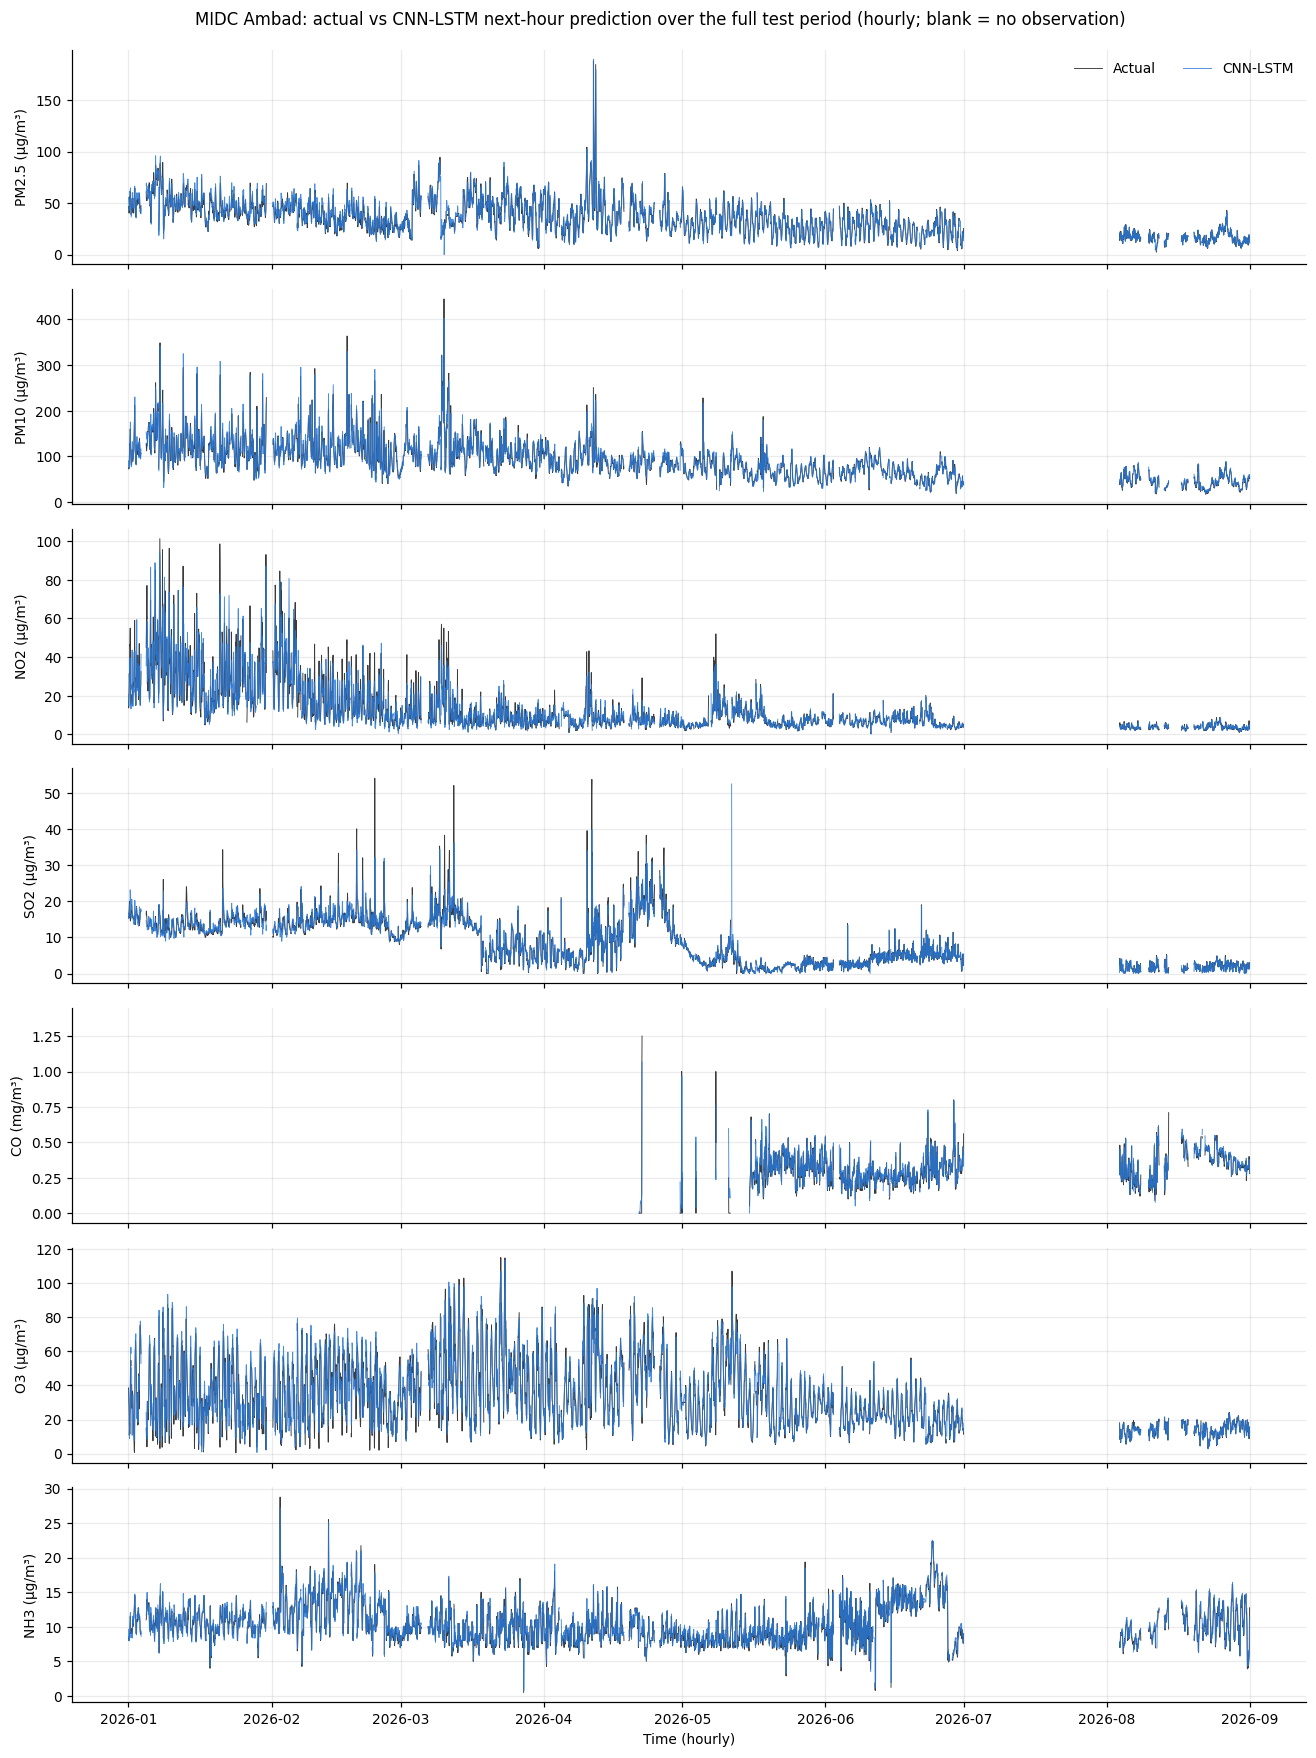

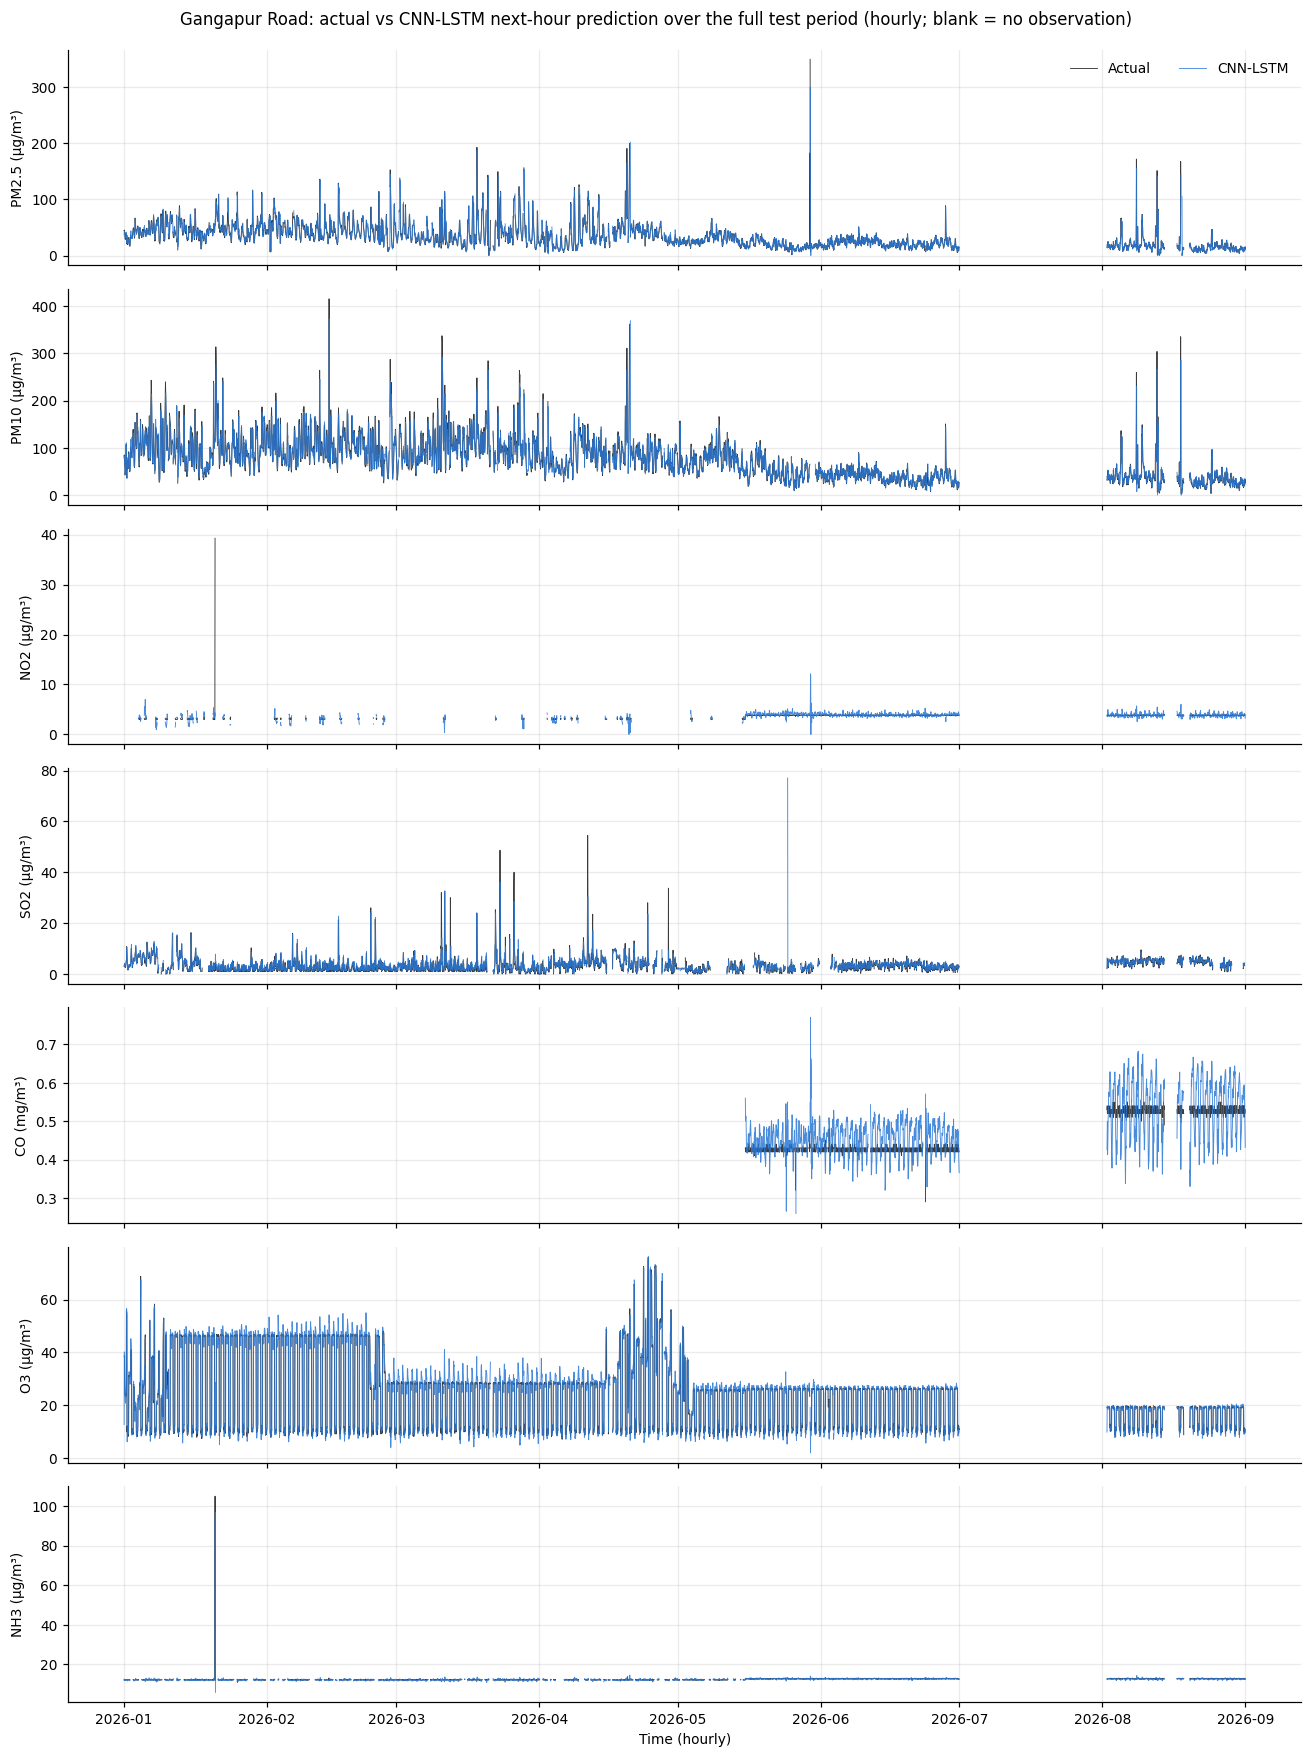

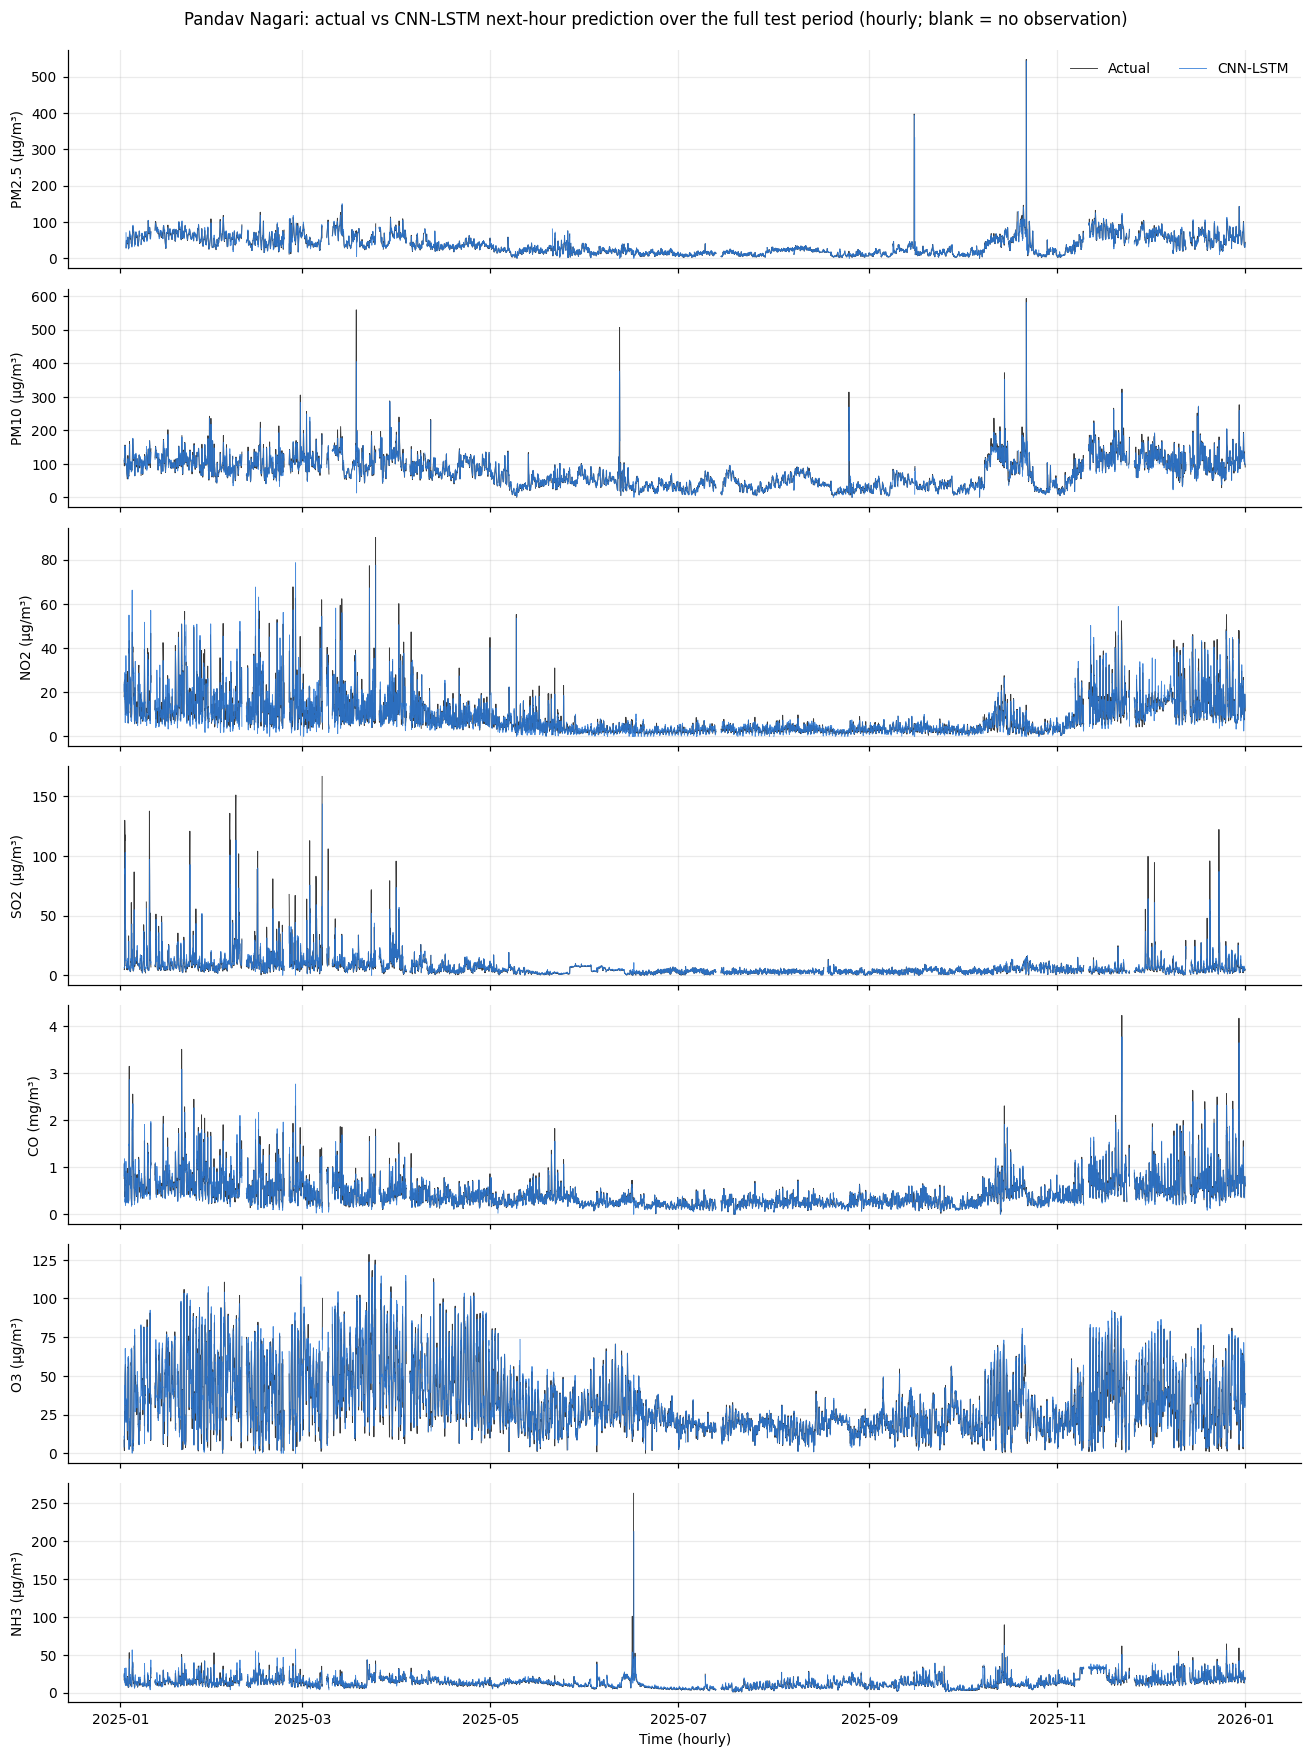

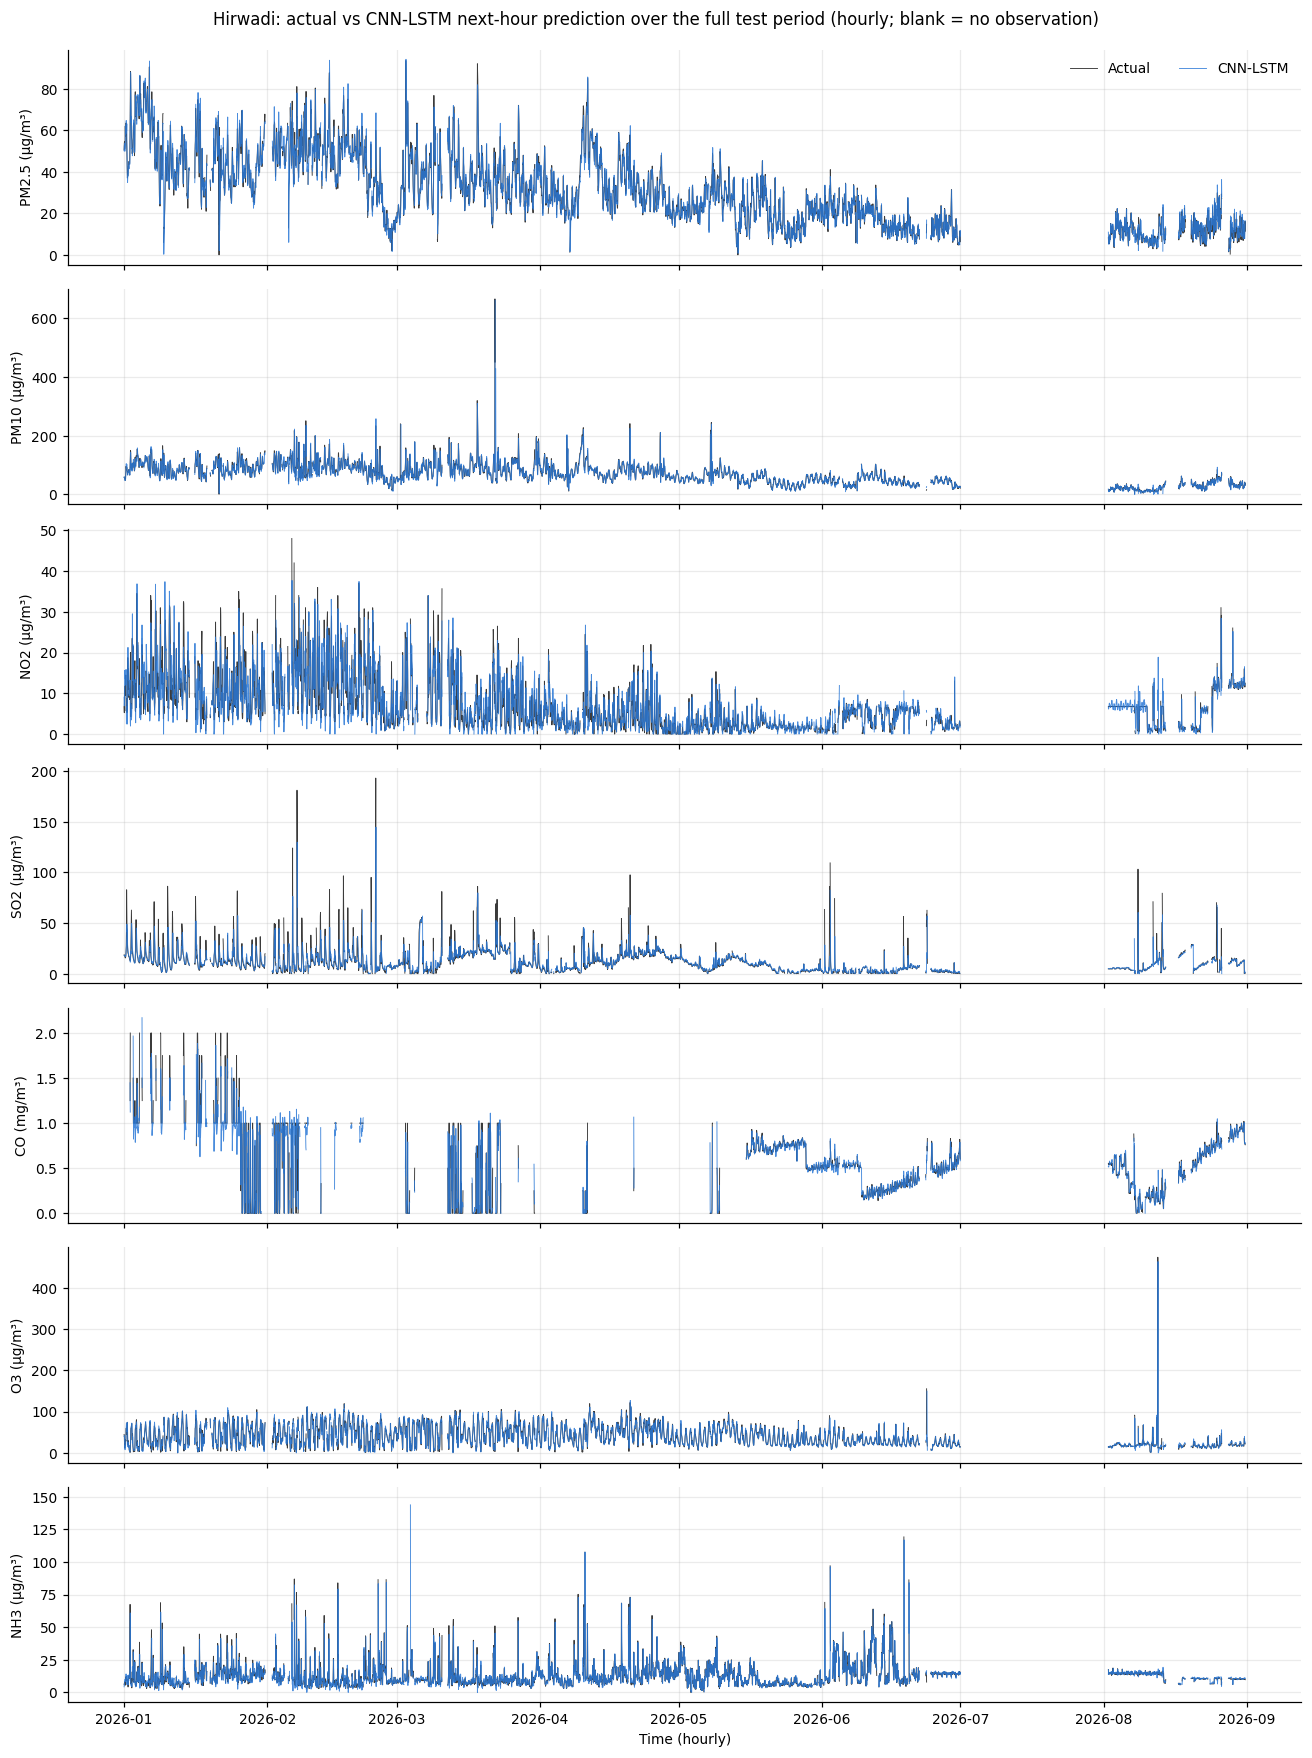

In [19]:
for s in windows:
    sub = predictions[predictions.station == s]
    fig, axes = plt.subplots(len(POLL), 1, figsize=(12, 16), sharex=True)
    for ax, p in zip(axes, POLL):
        g = sub[sub.pollutant == p].set_index("timestamp").sort_index()
        full = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq="h"))  # gaps stay blank
        ax.plot(full.index, full.actual, lw=0.6, color="#3b3b3b", label="Actual")
        ax.plot(full.index, full.cnn_lstm_pred, lw=0.6, color="#2a78d6", alpha=0.85,
                label="CNN-LSTM")
        ax.set_ylabel(f"{p} ({UNITS[p]})")
    axes[0].legend(ncol=2, loc="upper right", frameon=False)
    axes[-1].set_xlabel("Time (hourly)")
    fig.suptitle(f"{s}: actual vs CNN-LSTM next-hour prediction over the full test period "
                 f"(hourly; blank = no observation)", y=0.995)
    fig.tight_layout()
    savefig(fig, f"fig05_actual_vs_pred_{s.replace(' ', '_')}")

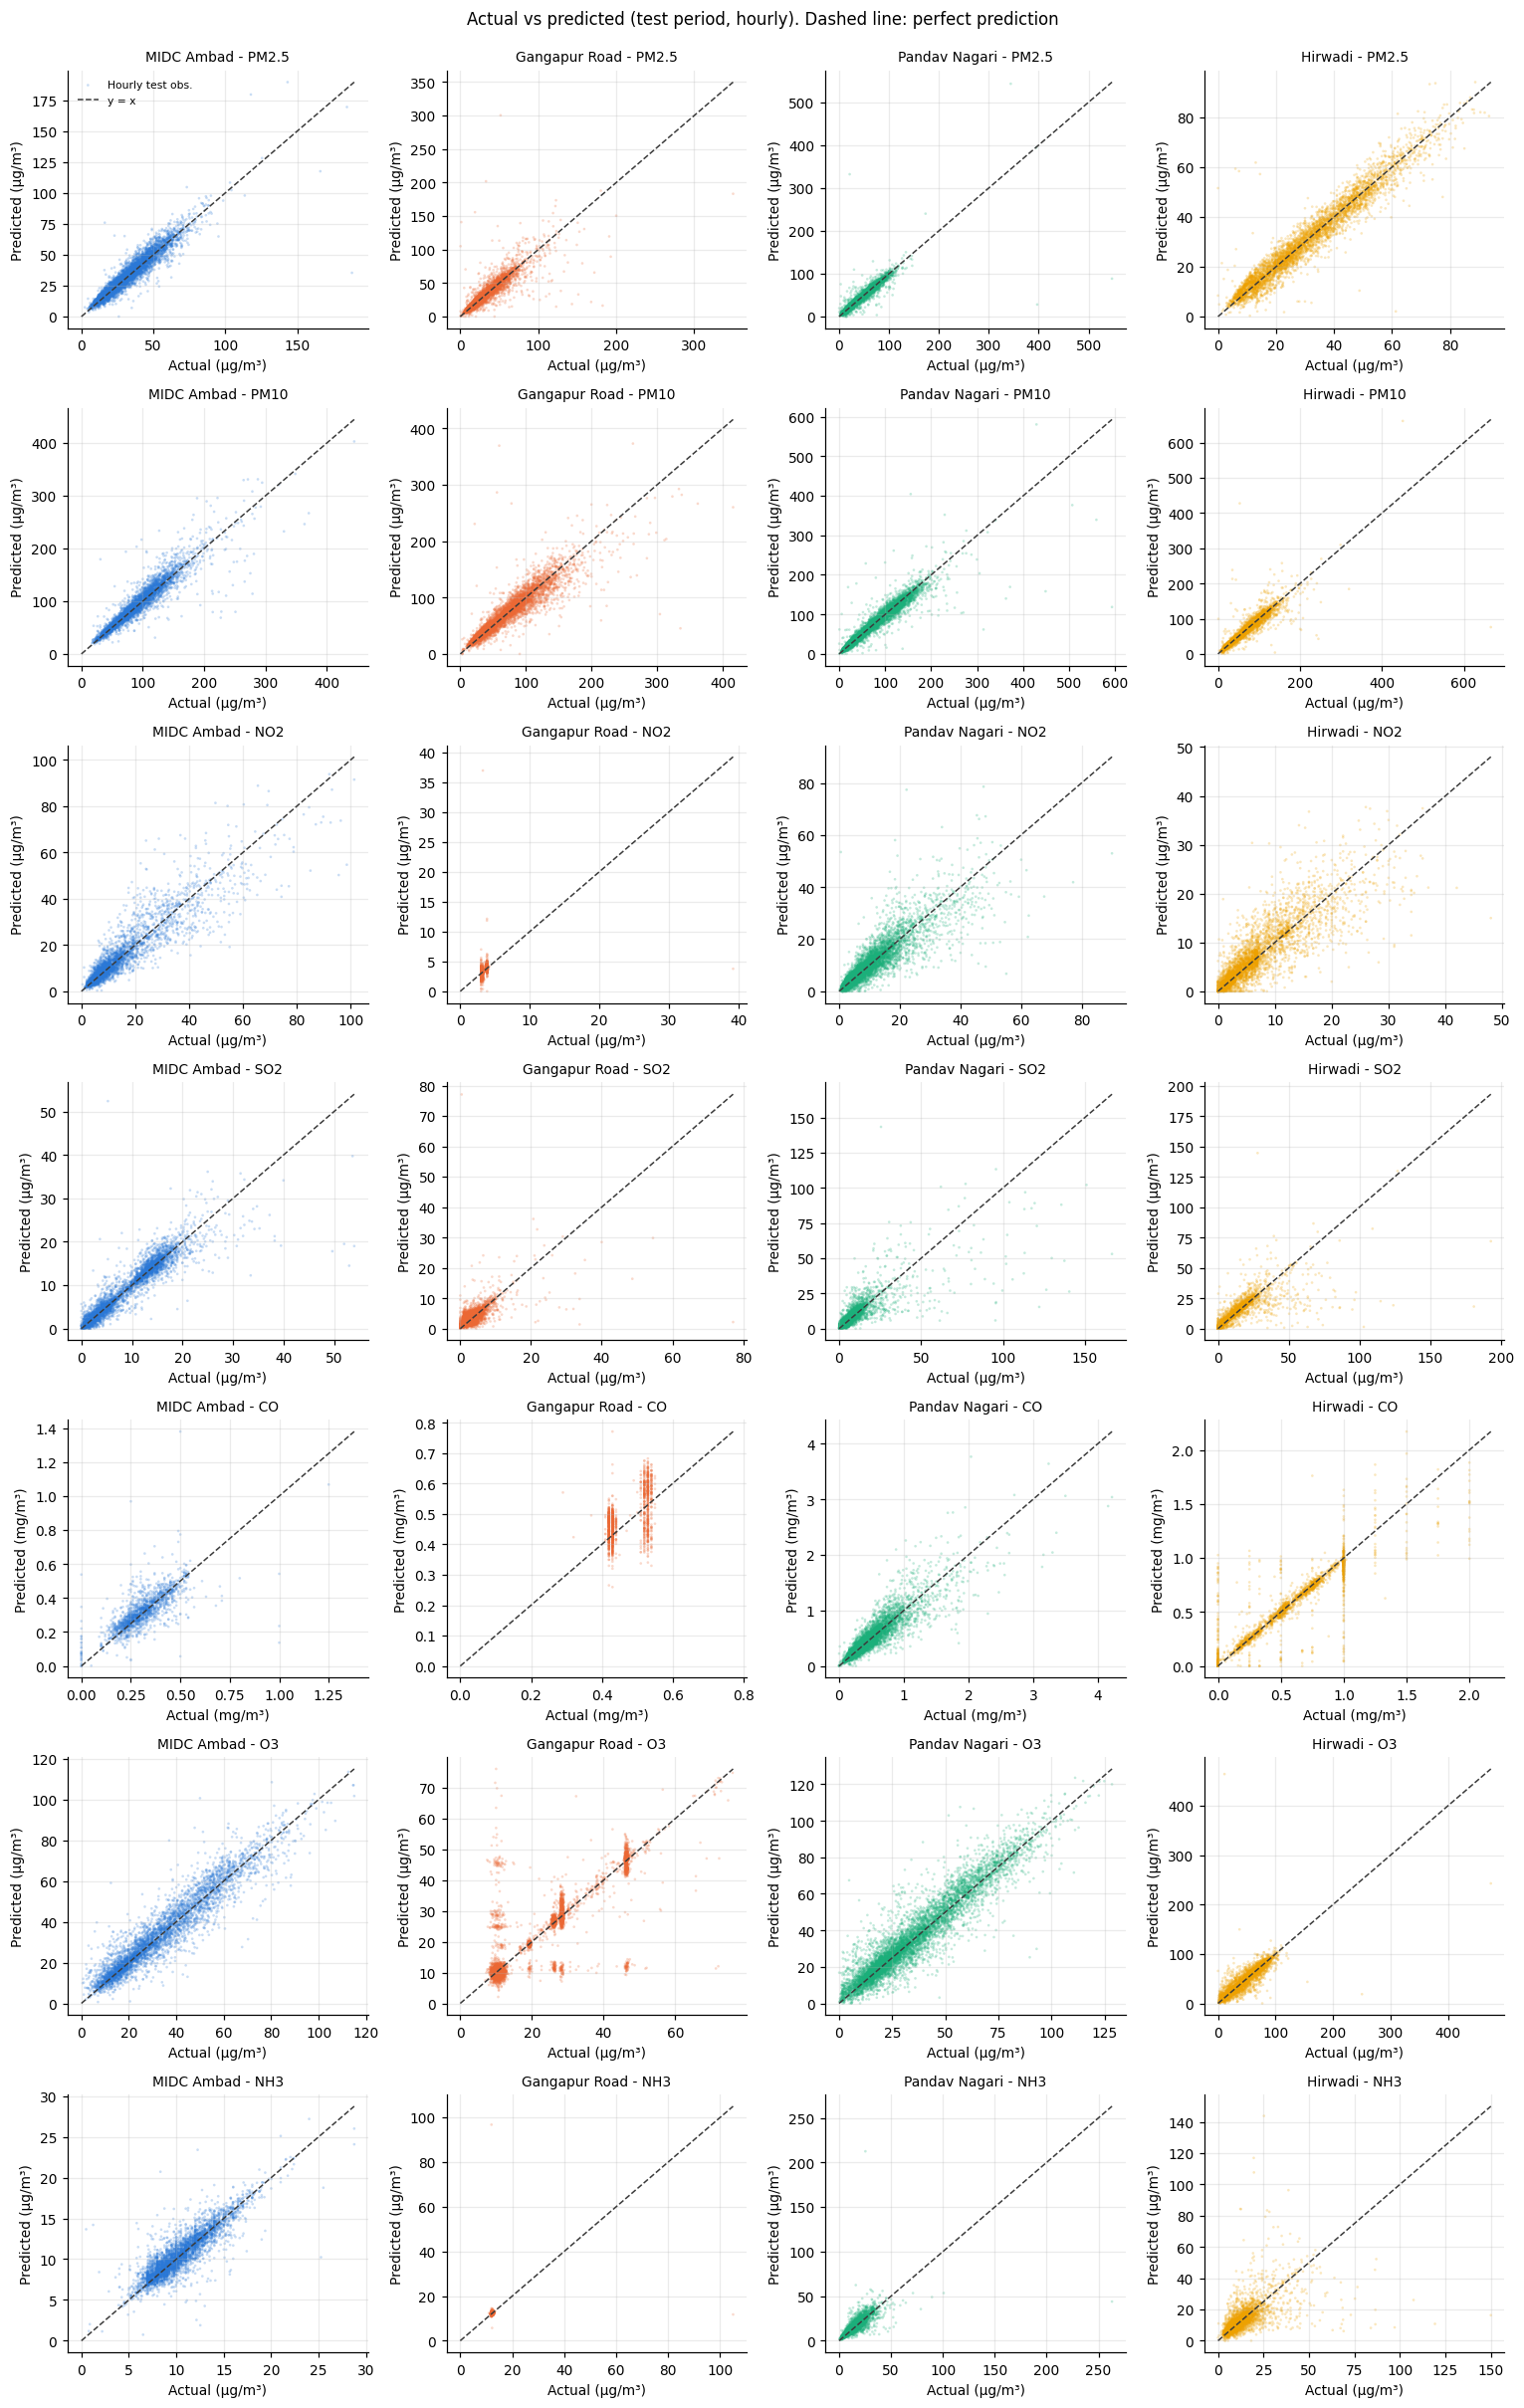

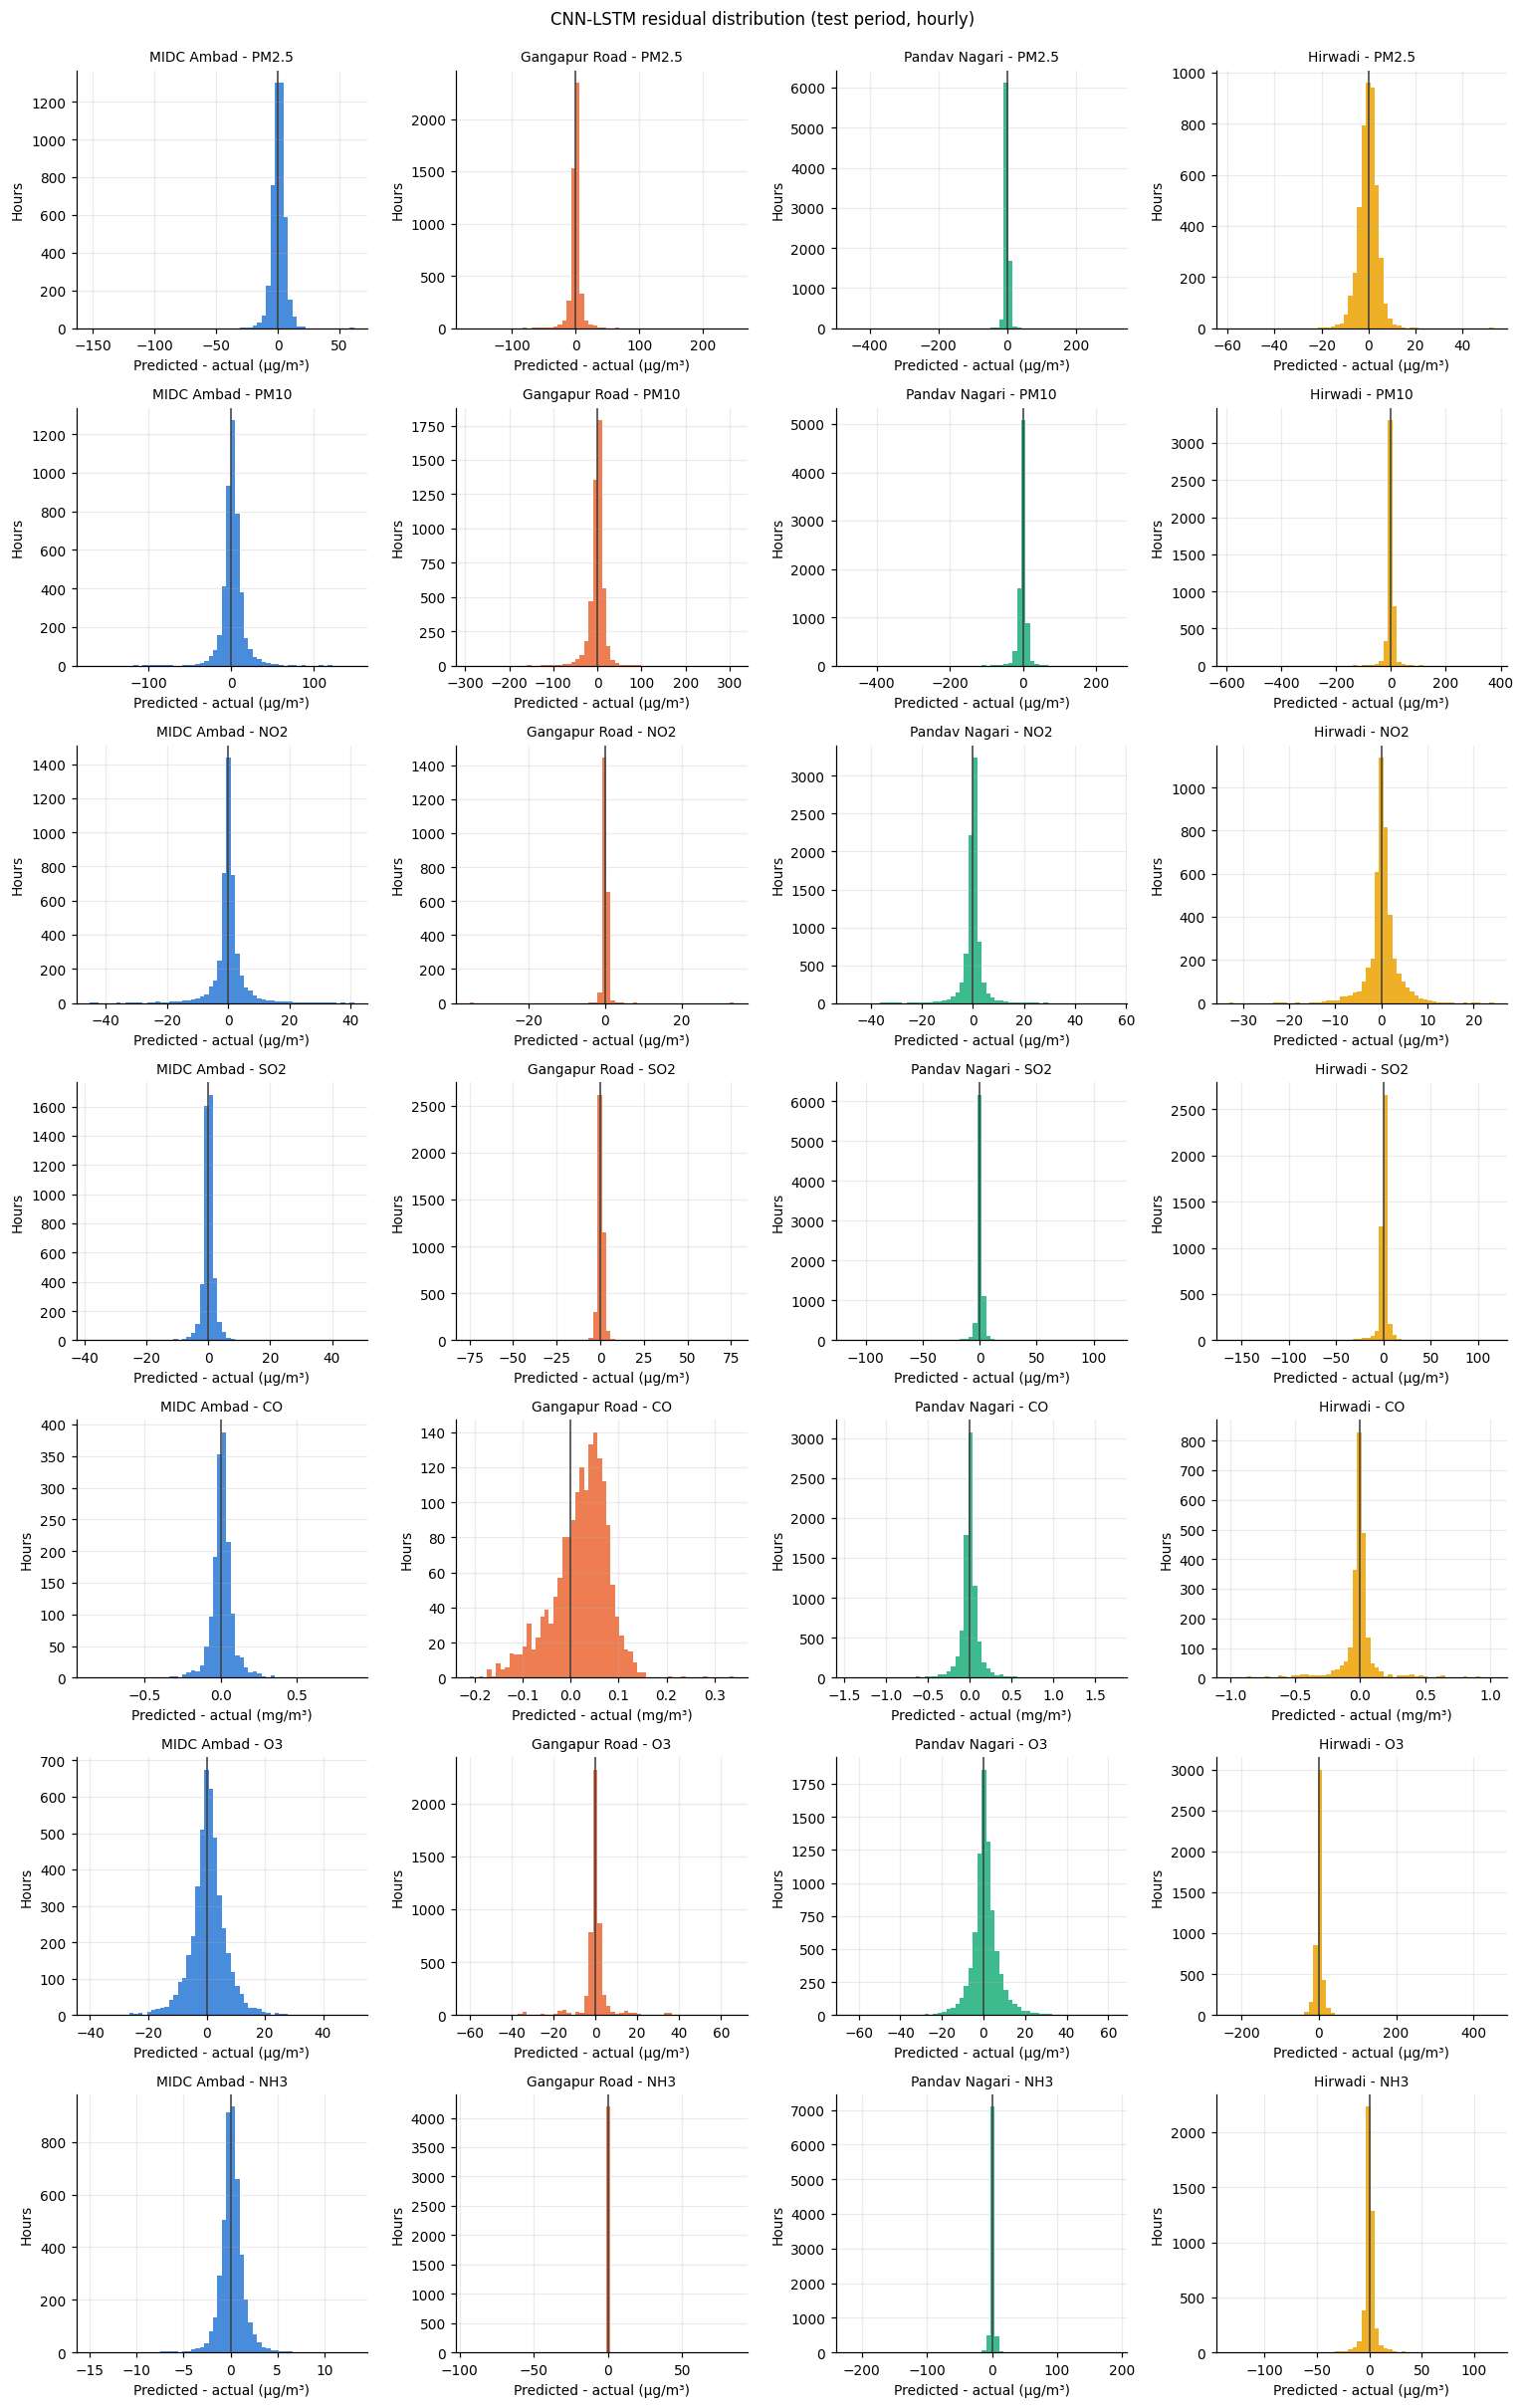

In [20]:
def grid_plot(kind, name, title):
    fig, axes = plt.subplots(len(POLL), 4, figsize=(14, 22))
    for j, s in enumerate(windows):
        for i, p in enumerate(POLL):
            ax = axes[i, j]
            g = predictions[(predictions.station == s) & (predictions.pollutant == p)]
            if kind == "scatter":
                ax.scatter(g.actual, g.cnn_lstm_pred, s=3, alpha=0.25, color=STATION_COLORS[s],
                           edgecolors="none", label="Hourly test obs.")
                lim = [0, max(g.actual.max(), g.cnn_lstm_pred.max())]
                ax.plot(lim, lim, color="#3b3b3b", lw=1, ls="--", label="y = x")
                ax.set_xlabel(f"Actual ({UNITS[p]})")
                ax.set_ylabel(f"Predicted ({UNITS[p]})")
            else:
                res = g.cnn_lstm_pred - g.actual
                ax.hist(res, bins=60, color=STATION_COLORS[s], alpha=0.85)
                ax.axvline(0, color="#3b3b3b", lw=1)
                ax.set_xlabel(f"Predicted - actual ({UNITS[p]})")
                ax.set_ylabel("Hours")
            ax.set_title(f"{s} - {p}", fontsize=9)
    if kind == "scatter":
        axes[0, 0].legend(frameon=False, fontsize=7)
    fig.suptitle(title, y=0.997)
    fig.tight_layout()
    savefig(fig, name)


grid_plot("scatter", "fig06_scatter_actual_vs_pred",
          "Actual vs predicted (test period, hourly). Dashed line: perfect prediction")
grid_plot("hist", "fig07_residuals", "CNN-LSTM residual distribution (test period, hourly)")

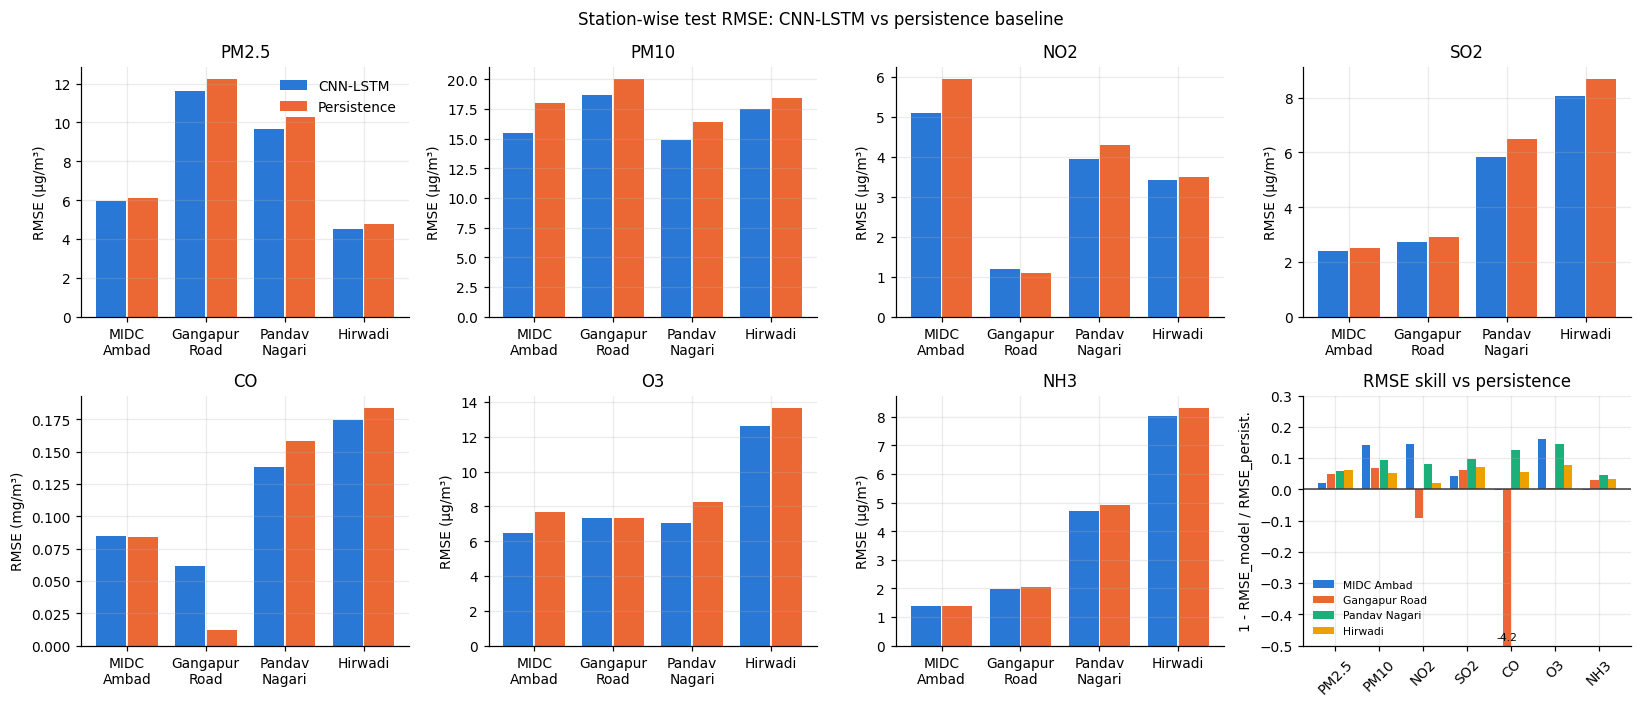

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
x = np.arange(len(windows))
for ax, p in zip(axes.flat, POLL):
    g = station_metrics[station_metrics.pollutant == p].set_index("station").loc[list(windows)]
    ax.bar(x - 0.2, g["CNN-LSTM RMSE"], 0.38, color="#2a78d6", label="CNN-LSTM")
    ax.bar(x + 0.2, g["Persistence RMSE"], 0.38, color="#eb6834", label="Persistence")
    ax.set_xticks(x, [s.replace(" ", "\n") for s in windows])
    ax.set_title(p)
    ax.set_ylabel(f"RMSE ({UNITS[p]})")
axes[0, 0].legend(frameon=False)
ax = axes.flat[-1]
for k, s in enumerate(windows):
    ax.bar(np.arange(len(POLL)) + (k - 1.5) * 0.2, skill_summary.loc[s, POLL], 0.19,
           color=STATION_COLORS[s], label=s)
SKILL_YLIM = (-0.5, 0.3)
for k, s in enumerate(windows):
    for j, p in enumerate(POLL):
        v = skill_summary.loc[s, p]
        if v < SKILL_YLIM[0]:  # label bars clipped by the axis instead of letting one dwarf all
            ax.annotate(f"{v:.1f}", (j + (k - 1.5) * 0.2, SKILL_YLIM[0]), ha="center",
                        va="bottom", fontsize=7, xytext=(0, 2), textcoords="offset points")
ax.set_ylim(*SKILL_YLIM)
ax.axhline(0, color="#3b3b3b", lw=1)
ax.set_xticks(range(len(POLL)), POLL, rotation=45)
ax.set_ylabel("1 - RMSE_model / RMSE_persist.")
ax.set_title("RMSE skill vs persistence")
ax.legend(frameon=False, fontsize=7)
fig.suptitle("Station-wise test RMSE: CNN-LSTM vs persistence baseline")
fig.tight_layout()
savefig(fig, "fig08_station_metrics")

## 15. Export summary

All tables, metrics, predictions, figures, models and preprocessing objects are in
`outputs/`. If `scripts/build_report.py` is present it builds the DOCX report from them
(every number in the report is read from these files).

In [22]:
with open(f"{OUT}/metrics/run_info.json", "w") as fh:
    json.dump({"versions": VERSIONS, "seed": SEED, "lookback_hours": LOOKBACK,
               "horizon_hours": 1, "k_neighbors": K_NEIGHBORS, "batch_size": BATCH,
               "max_epochs": EPOCHS, "patience": PATIENCE,
               "max_imputed_fraction": MAX_IMPUTED_FRACTION, "stuck_hours": STUCK_HOURS,
               "epochs_run": {s: len(h["loss"]) for s, h in histories.items()},
               "best_epoch": {s: int(np.argmin(h["val_loss"])) + 1 for s, h in histories.items()},
               "station_files": STATION_FILES}, fh, indent=2, default=str)
if os.path.exists("scripts/build_report.py"):
    import subprocess
    import sys
    try:
        import docx  # noqa: F401  (python-docx)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-docx"], check=True)
    subprocess.run([sys.executable, "scripts/build_report.py"], check=True)
if IN_COLAB:
    import shutil
    shutil.make_archive("nashik_outputs", "zip", OUT)
    files.download("nashik_outputs.zip")
print(sorted(glob.glob(f"{OUT}/**/*.*", recursive=True)))

Wrote outputs/Nashik_AQ_CNN_LSTM_Report.docx: 11 figures, 13 tables
['outputs/Nashik_AQ_CNN_LSTM_Report.docx', 'outputs/figures/fig01_missing_values.png', 'outputs/figures/fig02_historical_trends.png', 'outputs/figures/fig03_station_comparison.png', 'outputs/figures/fig04_loss_curves.png', 'outputs/figures/fig05_actual_vs_pred_Gangapur_Road.png', 'outputs/figures/fig05_actual_vs_pred_Hirwadi.png', 'outputs/figures/fig05_actual_vs_pred_MIDC_Ambad.png', 'outputs/figures/fig05_actual_vs_pred_Pandav_Nagari.png', 'outputs/figures/fig06_scatter_actual_vs_pred.png', 'outputs/figures/fig07_residuals.png', 'outputs/figures/fig08_station_metrics.png', 'outputs/metrics/model_selection_validation.csv', 'outputs/metrics/overall_pollutant_metrics.csv', 'outputs/metrics/rmse_skill_summary.csv', 'outputs/metrics/run_info.json', 'outputs/metrics/station_pollutant_metrics.csv', 'outputs/metrics/training_history.json', 'outputs/models/cnn_lstm_change_Gangapur_Road.keras', 'outputs/models/cnn_lstm_change_